# Entrega 02 — Implementação Analítica: Análise de Dados, Suporte à Decisão Clínica e Ética
## Diagnóstico precoce da Doença de Lyme por visão computacional do Eritema Migratório

| | |
|---|---|
| **Instituição** | FESA — Faculdade Engenheiro Salvador Arena |
| **Curso / Disciplina** | Engenharia de Computação — Análise de Dados |
| **Avaliação** | N1 — 2º Bimestre — Entrega 02 (continuação da Entrega 01) |
| **Dupla** | Fábio Gomes Celestino — RA 081220016<br>Murilo Trevejo Santos — RA 081220025 |
| **Patologia** | Doença de Lyme (borreliose de Lyme) — manifestação cutânea precoce: eritema migratório (EM) |
| **Dataset** | *Lyme Disease Rashes* (Kaggle): https://www.kaggle.com/datasets/sshikamaru/lyme-disease-rashes |
| **Repositório do projeto** | https://github.com/Trevejo/analise-de-dados-fesa-doenca-de-lyme |

<a href="https://colab.research.google.com/github/Trevejo/analise-de-dados-fesa-doenca-de-lyme/blob/main/notebooks/02_pipeline_analitica_cdss_etica_lyme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

**Roteiro do notebook:** (1) identificação e carregamento → (2) qualidade dos dados e pré-processamento clínico →
(3) métricas estatísticas, agrupamento e classificação → (4) interpretação para o CDSS → (5) análise crítica e ética →
(6) conclusões e referências.

## Seção 01 — Identificação, resgate clínico e carregamento da base

### 1.1 Cabeçalho do projeto
Integrantes da dupla, título, patologia e link da fonte original do dataset estão no quadro de identificação acima.

### 1.2 Síntese do problema clínico (resgate da Entrega 01)
A Doença de Lyme é uma zoonose multissistêmica causada por espiroquetas do complexo *Borrelia burgdorferi* *sensu lato*,
transmitidas pela picada de carrapatos do gênero *Ixodes*. Após a inoculação, a bactéria se multiplica na derme e migra
centrifugamente, produzindo o **eritema migratório (EM)**: uma mácula/placa eritematosa em expansão, com ≥ 5 cm, que surge
entre 3 e 30 dias após a picada. O EM é o **biomarcador clínico primário** da fase localizada precoce — as diretrizes
IDSA/AAN/ACR (2020) recomendam diagnosticá-lo e tratá-lo **clinicamente**, sem esperar sorologia, porque ELISA e Western blot
são negativos na maioria dos pacientes nas primeiras semanas (janela imunológica). O gargalo é visual: a minoria dos EM tem
o aspecto clássico "em alvo"; a maioria é homogênea (Smith *et al.*, 2002) e se confunde com celulite, picada de artrópode, tinea, urticária,
herpes-zóster e outras dermatoses. Sem tratamento (doxiciclina por 10 dias), a infecção pode disseminar-se e causar
paralisia facial, meningite, cardite com bloqueio atrioventricular e artrite de Lyme.

Nesta etapa, os **biomarcadores analisados** são digitais e extraídos das fotografias: intensidade e contraste do eritema
(espaço CIELAB), padrão radial centro→borda (proxy do aspecto em alvo), textura (descamação, vesículas), densidade de bordas
e tom de pele (ITA), além de *embeddings* de uma CNN pré-treinada. As **4 perguntas norteadoras** da Entrega 01 são:

1. **Agrupamento:** existem fenótipos visuais latentes entre as lesões de Lyme? → *Seção 3.B.2 (PCA + K-Means + t-SNE).*
2. **Classificação:** é possível diferenciar o EM de 12 diagnósticos diferenciais em imagens ruidosas? → *Seção 3.B.1.*
3. **Predição temporal:** como modelar a expansão da lesão no tempo? → *Seção 3.B.3 (discussão de viabilidade: a base não tem dimensão temporal).*
4. **Suporte à decisão (CDSS):** como integrar probabilidades calibradas e explicabilidade em condutas? → *Seção 4.*

### 1.3 Configuração do ambiente (reprodutibilidade)
A célula abaixo funciona tanto no **Google Colab** quanto em um Jupyter local: se a base não for encontrada,
o repositório público do projeto é clonado (imagens + metadados + *cache* de atributos). Todas as etapas
aleatórias usam a semente fixa `RANDOM_STATE = 42`.

In [1]:
# ---------------------------------------------------------------
# 1.3 Ambiente: bibliotecas, semente e localizacao dos dados
# ---------------------------------------------------------------
import os, sys, subprocess, warnings, importlib

# shap e scikit-image ja vem no Colab; instala apenas se faltar
for pacote, modulo in [('shap', 'shap'), ('scikit-image', 'skimage')]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pacote], check=True)

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from PIL import Image
from scipy import stats
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from skimage.color import rgb2lab, rgb2hsv
from skimage.feature import graycomatrix, graycoprops, canny
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.calibration import calibration_curve
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, f1_score, brier_score_loss, silhouette_score,
                             davies_bouldin_score, adjusted_rand_score)

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', module='tqdm')
import shap
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

REPO_URL = 'https://github.com/Trevejo/analise-de-dados-fesa-doenca-de-lyme.git'
CANDIDATOS = ['..', '.', '/content/analise-de-dados-fesa-doenca-de-lyme']
ROOT = next((c for c in CANDIDATOS if os.path.exists(os.path.join(c, 'data', 'metadata_lyme_rashes.csv'))), None)
if ROOT is None:  # execucao no Colab sem a base: clona o repositorio publico
    subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, CANDIDATOS[-1]], check=True)
    ROOT = CANDIDATOS[-1]

IMG_DIR = os.path.join(ROOT, 'data', 'DataSplit', 'image_folder 2')
CACHE_DIR = os.path.join(ROOT, 'data', 'cache')
os.makedirs(CACHE_DIR, exist_ok=True)

# Paleta acessivel (validada para daltonismo): azul = controles, laranja = Lyme
COR_NEG, COR_POS, COR_3, COR_4 = '#2a78d6', '#eb6834', '#1baf7a', '#6250d6'
COR_NEUTRA, COR_TEXTO = '#898781', '#52514e'
ROTULO = {0: 'Controle (diagnósticos diferenciais)', 1: 'Lyme (eritema migratório)'}
PALETA_CLASSE = {ROTULO[0]: COR_NEG, ROTULO[1]: COR_POS}
CMAP_DIV = LinearSegmentedColormap.from_list('azul_cinza_vermelho', ['#184f95', '#6da7ec', '#f0efec', '#ef8f8e', '#b3302f'])
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 9.5, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7', 'axes.grid': True,
    'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.axisbelow': True, 'xtick.color': COR_TEXTO,
    'ytick.color': COR_TEXTO, 'legend.frameon': False,
})

print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__}')
print('Executando no Google Colab' if 'google.colab' in sys.modules else 'Executando em Jupyter local')
print('Base localizada:', os.path.exists(IMG_DIR))

Python 3.12.14 | pandas 3.1.0 | numpy 2.5.4
Executando em Jupyter local
Base localizada: True


### 1.4 Ingestão e inspeção inicial da base
A base tabular `metadata_lyme_rashes.csv` (construída na Entrega 01) descreve cada uma das 5.059 fotografias
dermatológicas do dataset *Lyme Disease Rashes* (Kaggle). Abaixo: dimensões (`shape`), tipos (`info()`) e amostra (`head()`).

In [2]:
# ---------------------------------------------------------------
# 1.4 Ingestao da base de metadados (1 linha = 1 fotografia)
# ---------------------------------------------------------------
df_meta = pd.read_csv(os.path.join(ROOT, 'data', 'metadata_lyme_rashes.csv'))
assert df_meta['filename'].is_unique, 'nomes de arquivo devem ser unicos'

print('Dimensões da base (linhas, colunas):', df_meta.shape)
print()
df_meta.info()
display(df_meta.head())

Dimensões da base (linhas, colunas): (5059, 20)

<class 'pandas.DataFrame'>
RangeIndex: 5059 entries, 0 to 5058
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   filename         5059 non-null   str    
 1   file_size_bytes  5059 non-null   int64  
 2   binary_class     5059 non-null   str    
 3   condition        5059 non-null   str    
 4   split            5059 non-null   str    
 5   width            5059 non-null   int64  
 6   height           5059 non-null   int64  
 7   aspect_ratio     5059 non-null   float64
 8   color_mode       5059 non-null   str    
 9   channels         5059 non-null   int64  
 10  mean_r           5059 non-null   float64
 11  mean_g           5059 non-null   float64
 12  mean_b           5059 non-null   float64
 13  std_r            5059 non-null   float64
 14  std_g            5059 non-null   float64
 15  std_b            5059 non-null   float64
 16  brightness       5059 

,filename,file_size_bytes,binary_class,condition,split,width,height,aspect_ratio,color_mode,channels,mean_r,mean_g,mean_b,std_r,std_g,std_b,brightness,contrast,erythema_index,corrupted
0,Erythema Migrans199.jpg,5742,Positive,Erythema Migrans,train,207,244,0.8484,RGB,3,134.25,106.49,85.90,81.93,58.35,56.41,112.44,62.83,27.76,False
1,bullseye rash165.jpg,2580,Positive,bullseye rash,train,194,260,0.7462,RGB,3,172.30,146.40,136.11,44.90,40.31,38.93,152.97,40.94,25.90,False
2,bullseye rash319.jpg,7353,Positive,bullseye rash,train,225,225,1.0000,RGB,3,166.44,145.67,124.06,49.91,49.38,51.94,149.42,48.72,20.77,False
3,EM rash405.jpg,4897,Positive,EM rash,test,259,194,1.3351,RGB,3,76.36,53.89,52.27,93.65,68.00,65.61,60.43,75.15,22.47,False
4,Erythema Migrans327.jpg,6529,Positive,Erythema Migrans,train,276,182,1.5165,RGB,3,140.68,124.94,131.36,71.12,74.01,72.07,130.38,71.92,15.74,False


### 1.5 Dicionário resumido e extração dos biomarcadores visuais digitais
Na Entrega 01 mostramos que a cor média isolada **não** separa Lyme dos controles. Por isso, nesta etapa cada
fotografia é convertida em dois conjuntos de atributos:

1. **Biomarcadores visuais interpretáveis** (calculados com `scikit-image`), que traduzem os critérios que o
   dermatologista usa no exame físico: intensidade do eritema, contraste da lesão em relação à pele vizinha,
   padrão radial centro→borda (proxy do aspecto "em alvo"), textura/descamação e tom de pele;
2. ***Embeddings* profundos** de uma rede convolucional pré-treinada no ImageNet (*transfer learning*), que
   capturam forma, borda e padrão espacial da lesão em um vetor numérico.

Como a extração percorre todas as imagens (≈ 2 min para biomarcadores e ≈ 5–10 min para os *embeddings* em CPU),
os resultados são gravados em `data/cache/` e reaproveitados nas execuções seguintes.

In [3]:
# ---------------------------------------------------------------
# 1.5 Dicionario resumido dos atributos usados na Entrega 02
# ---------------------------------------------------------------
dicionario = pd.DataFrame([
    ('binary_class',              'Categórico', '—',            'Desfecho: Positive = eritema migratório (Lyme); Negative = diagnóstico diferencial'),
    ('condition',                 'Categórico', '15 classes',   'Diagnóstico específico (3 rótulos de EM + 12 diferenciais)'),
    ('split',                     'Categórico', 'train/val/test','Partição oficial estratificada do dataset'),
    ('width, height',             'Inteiro',    'pixels',       'Resolução da fotografia (atributo de aquisição)'),
    ('brightness, contrast',      'Contínuo',   '0–255',        'Luminância média e desvio-padrão (qualidade da foto)'),
    ('erythema_index',            'Contínuo',   'R−G (0–255)',  'Índice de eritema clássico (hiperemia média)'),
    ('lab_a_mean',                'Contínuo',   'a* CIELAB',    'Vermelhidão média perceptual (eixo verde→vermelho)'),
    ('a_p90_minus_p50',           'Contínuo',   'Δa* CIELAB',   'Contraste eritematoso: quanto a área mais vermelha excede a pele típica da foto'),
    ('a_std',                     'Contínuo',   'a* CIELAB',    'Heterogeneidade da vermelhidão na imagem'),
    ('saturation_mean',           'Contínuo',   '0–1 (HSV)',    'Saturação média da cor (vivacidade da lesão)'),
    ('radial_a_center_minus_mid', 'Contínuo',   'Δa* CIELAB',   'Centro − anel intermediário: >0 lesão centralizada; <0 clareamento central (alvo)'),
    ('radial_a_range',            'Contínuo',   'Δa* CIELAB',   'Amplitude do perfil radial de vermelhidão (anéis concêntricos)'),
    ('radial_a_sign_changes',     'Discreto',   'contagem',     'Alternâncias claro/escuro no perfil radial (padrão anelar)'),
    ('glcm_contrast / homogeneity / energy / correlation', 'Contínuo', 'adimensional', 'Textura de Haralick (descamação, vesículas, pápulas)'),
    ('gray_entropy',              'Contínuo',   'bits',         'Complexidade/desordem da textura'),
    ('edge_density',              'Contínuo',   'fração 0–1',   'Densidade de bordas (Canny): lesões múltiplas/irregulares'),
    ('sharpness_lap',             'Contínuo',   'nível de cinza','Nitidez (energia do Laplaciano) — controle de foco'),
    ('skin_fraction',             'Contínuo',   'fração 0–1',   'Fração de pixels classificados como pele (YCbCr)'),
    ('ita_deg',                   'Contínuo',   'graus (°)',    'Ângulo Tipológico Individual da pele perilesional — proxy de fototipo'),
    ('emb_0 … emb_n',             'Contínuo',   'adimensional', 'Embedding da CNN pré-treinada (média global dos mapas de ativação)'),
], columns=['Atributo', 'Tipo', 'Unidade', 'Significado clínico / computacional'])
display(dicionario.style.hide(axis='index'))

Atributo,Tipo,Unidade,Significado clínico / computacional
binary_class,Categórico,—,Desfecho: Positive = eritema migratório (Lyme); Negative = diagnóstico diferencial
condition,Categórico,15 classes,Diagnóstico específico (3 rótulos de EM + 12 diferenciais)
split,Categórico,train/val/test,Partição oficial estratificada do dataset
"width, height",Inteiro,pixels,Resolução da fotografia (atributo de aquisição)
"brightness, contrast",Contínuo,0–255,Luminância média e desvio-padrão (qualidade da foto)
erythema_index,Contínuo,R−G (0–255),Índice de eritema clássico (hiperemia média)
lab_a_mean,Contínuo,a* CIELAB,Vermelhidão média perceptual (eixo verde→vermelho)
a_p90_minus_p50,Contínuo,Δa* CIELAB,Contraste eritematoso: quanto a área mais vermelha excede a pele típica da foto
a_std,Contínuo,a* CIELAB,Heterogeneidade da vermelhidão na imagem
saturation_mean,Contínuo,0–1 (HSV),Saturação média da cor (vivacidade da lesão)


In [4]:
# ---------------------------------------------------------------
# 1.5 Extracao dos biomarcadores visuais interpretaveis (com cache)
# ---------------------------------------------------------------
BIO_CACHE = os.path.join(CACHE_DIR, 'biomarcadores_imagem.csv')

def caminho_imagem(linha):
    return os.path.join(IMG_DIR, linha['binary_class'], linha['filename'])

def mascara_pele(rgb):
    """Segmentacao classica de pele no espaco YCbCr (Chai & Ngan, 1999)."""
    ycc = np.asarray(Image.fromarray(rgb).convert('YCbCr'), dtype=np.float32)
    cb, cr = ycc[..., 1], ycc[..., 2]
    return (cr >= 133) & (cr <= 180) & (cb >= 77) & (cb <= 135)

def extrair_biomarcadores(caminho):
    rgb = np.asarray(Image.open(caminho).convert('RGB'))
    lab = rgb2lab(rgb)
    L, a, b = lab[..., 0], lab[..., 1], lab[..., 2]
    f = {'lab_L_mean': L.mean(), 'lab_a_mean': a.mean(), 'lab_b_mean': b.mean(),
         'a_p90_minus_p50': np.percentile(a, 90) - np.median(a), 'a_std': a.std(),
         'saturation_mean': rgb2hsv(rgb)[..., 1].mean()}

    # Tom de pele (ITA) medido apenas na pele perilesional: pixels de pele com a* abaixo da mediana
    pele = mascara_pele(rgb)
    f['skin_fraction'] = pele.mean()
    if pele.sum() >= 200:
        perilesional = pele & (a <= np.median(a[pele]))
        Lp, bp = L[perilesional].mean(), max(b[perilesional].mean(), 1e-3)
        f['ita_deg'] = np.degrees(np.arctan((Lp - 50) / bp))
    else:
        f['ita_deg'] = np.nan  # mascara de pele insuficiente -> valor ausente (investigado na Secao 2)

    # Perfil radial de vermelhidao em 5 aneis concentricos a partir do centro da foto
    h, w = a.shape
    yy, xx = np.mgrid[0:h, 0:w]
    raio = np.sqrt(((yy - h / 2) / (h / 2)) ** 2 + ((xx - w / 2) / (w / 2)) ** 2)
    aneis = np.array([a[(raio >= r0) & (raio < r0 + 0.2)].mean() for r0 in np.arange(0, 1.0, 0.2)])
    d = np.diff(aneis)
    f['radial_a_center_minus_mid'] = aneis[0] - aneis[2]
    f['radial_a_range'] = aneis.max() - aneis.min()
    f['radial_a_sign_changes'] = int(np.sum(np.sign(d[1:]) != np.sign(d[:-1])))

    # Textura (matriz de co-ocorrencia de Haralick), entropia, bordas e nitidez
    cinza = np.asarray(Image.fromarray(rgb).convert('L'))
    glcm = graycomatrix((cinza // 8).astype(np.uint8), [1, 3], [0, np.pi / 2], levels=32, symmetric=True, normed=True)
    for prop in ['contrast', 'homogeneity', 'energy', 'correlation']:
        f['glcm_' + prop] = graycoprops(glcm, prop).mean()
    hist = np.bincount(cinza.ravel(), minlength=256) / cinza.size
    f['gray_entropy'] = -(hist[hist > 0] * np.log2(hist[hist > 0])).sum()
    f['edge_density'] = canny(cinza / 255.0, sigma=2).mean()
    g = cinza.astype(np.float32)
    f['sharpness_lap'] = np.abs(np.diff(g, 2, axis=0)).mean() + np.abs(np.diff(g, 2, axis=1)).mean()
    return f

if os.path.exists(BIO_CACHE):
    df_bio = pd.read_csv(BIO_CACHE)
    print(f'Biomarcadores carregados do cache: {df_bio.shape}')
else:
    linhas = []
    for i, linha in df_meta.iterrows():
        linhas.append({'filename': linha['filename'], **extrair_biomarcadores(caminho_imagem(linha))})
    df_bio = pd.DataFrame(linhas)
    df_bio.to_csv(BIO_CACHE, index=False)
    print(f'Biomarcadores extraidos e salvos em cache: {df_bio.shape}')

df = df_meta.merge(df_bio, on='filename', how='left', validate='one_to_one')
df['y'] = (df['binary_class'] == 'Positive').astype(int)
df['classe'] = df['y'].map(ROTULO)
display(df[['filename', 'classe', 'lab_a_mean', 'a_p90_minus_p50', 'radial_a_center_minus_mid', 'glcm_contrast', 'ita_deg']].head())

Biomarcadores carregados do cache: (5059, 19)


,filename,classe,lab_a_mean,a_p90_minus_p50,radial_a_center_minus_mid,glcm_contrast,ita_deg
0,Erythema Migrans199.jpg,Lyme (eritema migratório),8.561951,12.506663,17.106348,4.573826,1.066060
1,bullseye rash165.jpg,Lyme (eritema migratório),7.967913,12.845813,12.103854,1.127757,54.531286
2,bullseye rash319.jpg,Lyme (eritema migratório),4.726668,13.927878,-1.085380,6.795982,57.530221
3,EM rash405.jpg,Lyme (eritema migratório),8.495068,26.984134,15.454993,3.244564,45.106583
4,Erythema Migrans327.jpg,Lyme (eritema migratório),8.165019,10.117948,11.140520,8.032311,45.983200


In [5]:
# ---------------------------------------------------------------
# 1.5 Embeddings profundos via transfer learning (com cache)
# ---------------------------------------------------------------
import torch
from torchvision import models

BACKBONE = 'convnext_tiny'   # ConvNeXt-Tiny pre-treinada no ImageNet-1k (torchvision)
EMB_CACHE = os.path.join(CACHE_DIR, f'embeddings_{BACKBONE}.npz')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

def carregar_backbone():
    pesos = models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1
    return models.convnext_tiny(weights=pesos).eval().to(DEVICE), pesos.transforms()

if os.path.exists(EMB_CACHE):
    pacote = np.load(EMB_CACHE, allow_pickle=True)
    assert (pacote['filename'] == df['filename'].values).all()
    EMB, THUMBS = pacote['emb'].astype(np.float32), pacote['thumb16'].astype(np.float32)
    print(f'Embeddings carregados do cache: {EMB.shape} (dispositivo disponivel: {DEVICE})')
else:
    rede, transformar = carregar_backbone()
    caminhos = [caminho_imagem(l) for _, l in df.iterrows()]
    lotes, miniaturas = [], []
    with torch.no_grad():
        for i in range(0, len(caminhos), 64):
            imgs = [Image.open(c).convert('RGB') for c in caminhos[i:i + 64]]
            x = torch.stack([transformar(im) for im in imgs]).to(DEVICE)
            lotes.append(rede.features(x).mean(dim=(2, 3)).cpu().numpy())   # media global (GAP) por canal
            miniaturas += [np.asarray(im.convert('L').resize((16, 16)), dtype=np.uint8).ravel() for im in imgs]
    EMB, THUMBS = np.concatenate(lotes).astype(np.float32), np.stack(miniaturas).astype(np.float32)
    np.savez_compressed(EMB_CACHE, emb=EMB.astype(np.float16), thumb16=THUMBS.astype(np.uint8), filename=df['filename'].values)
    print(f'Embeddings extraidos e salvos em cache: {EMB.shape}')

print(f'Cada fotografia -> vetor de {EMB.shape[1]} atributos profundos + {df_bio.shape[1] - 1} biomarcadores interpretaveis')

Embeddings carregados do cache: (5059, 768) (dispositivo disponivel: cpu)
Cada fotografia -> vetor de 768 atributos profundos + 18 biomarcadores interpretaveis


## Seção 02 — Tratamento da qualidade dos dados e pré-processamento clínico
Cada decisão de limpeza abaixo é justificada sob a ótica médica: em um problema diagnóstico, remover ou imputar um dado
muda **quem** o modelo aprende a reconhecer como doente. Toda transformação que "aprende" parâmetros dos dados (medianas,
escalas) é ajustada **somente no conjunto de desenvolvimento** (treino + validação), nunca no teste.

### 2.1 Dados faltantes (missing values)

In [6]:
# ---------------------------------------------------------------
# 2.1 Quantificacao exata de valores ausentes (% por atributo)
# ---------------------------------------------------------------
BIOMARCADORES = [c for c in df_bio.columns if c != 'filename']
ausentes_obs = (df[list(df_meta.columns) + BIOMARCADORES].isna().mean() * 100).rename('% ausente')

# Variaveis clinicas que um prontuario de Lyme teria, mas que a fonte (fotos coletadas da web) nao registra
CLINICAS_AUSENTES = ['Idade', 'Sexo biológico', 'Fototipo (Fitzpatrick)', 'Local anatômico da lesão',
                     'Diâmetro da lesão (cm)', 'Dias desde a picada / início', 'Exposição a carrapato / área endêmica',
                     'Sintomas sistêmicos (febre, artralgia)', 'Sorologia (ELISA / Western blot)', 'País / região']
ausentes_clin = pd.Series(100.0, index=CLINICAS_AUSENTES, name='% ausente')

tabela_ausentes = pd.concat([
    ausentes_obs.to_frame().assign(Origem='Atributo observado (imagem/metadado)'),
    ausentes_clin.to_frame().assign(Origem='Variável clínica não registrada na fonte'),
])
print('Atributos observados com algum valor ausente:')
display(tabela_ausentes[(tabela_ausentes['% ausente'] > 0) & (tabela_ausentes['Origem'].str.startswith('Atributo'))].round(2))
print(f"Atributos observados 100% completos: {(ausentes_obs == 0).sum()} de {len(ausentes_obs)}")
print(f"Variáveis clínicas estruturalmente ausentes (100%): {len(ausentes_clin)}")

Atributos observados com algum valor ausente:


,% ausente,Origem
ita_deg,0.3,Atributo observado (imagem/metadado)


Atributos observados 100% completos: 37 de 38
Variáveis clínicas estruturalmente ausentes (100%): 10


In [7]:
# ---------------------------------------------------------------
# 2.1 O ITA ausente e aleatorio (MCAR) ou informativo (MNAR)?
# ---------------------------------------------------------------
df['ita_ausente'] = df['ita_deg'].isna()
comparacao = df.groupby('ita_ausente')[['skin_fraction', 'brightness', 'lab_L_mean', 'y']].median()
comparacao.index = ['ITA calculado', 'ITA ausente']
comparacao['n'] = df.groupby('ita_ausente').size().values
display(comparacao.round(3))

u = stats.mannwhitneyu(df.loc[df.ita_ausente, 'brightness'], df.loc[~df.ita_ausente, 'brightness'])
print(f'Mann-Whitney (brilho, ausente vs presente): p = {u.pvalue:.2e}')
print('Condições das fotos com ITA ausente:', df.loc[df.ita_ausente, 'condition'].value_counts().to_dict())

# Imputacao descritiva: mediana estratificada por grupo clinico (usada SOMENTE nas estatisticas descritivas)
mediana_por_grupo = df.groupby('y')['ita_deg'].median()
df['ita_deg_imput'] = df['ita_deg'].fillna(df['y'].map(mediana_por_grupo))
print('Mediana do ITA por grupo usada na imputação descritiva:', mediana_por_grupo.round(2).rename(ROTULO).to_dict())

,skin_fraction,brightness,lab_L_mean,y,n
ITA calculado,0.811,138.69,57.002,0.0,5044
ITA ausente,0.000,124.23,53.402,0.0,15


Mann-Whitney (brilho, ausente vs presente): p = 2.07e-01
Condições das fotos com ITA ausente: {'pityriasis rosea': 4, 'Fixed drug eruption': 3, 'superficial erythema annulare centrifugum': 3, 'Erythema marginatum': 2, 'tinea corporis': 1, 'serum sickness-like reactions': 1, 'Bacterial cellulitis': 1}
Mediana do ITA por grupo usada na imputação descritiva: {'Controle (diagnósticos diferenciais)': 33.63, 'Lyme (eritema migratório)': 37.4}


**Leitura e decisão — dados faltantes.**
- **Atributos observados:** 37 de 38 colunas estão 100% completas. A única com ausência é o `ita_deg` (15 fotos = 0,3%).
  O ITA fica ausente quando a máscara de pele encontra menos de 200 pixels: as 15 fotos têm fração de pele mediana 0, o
  brilho não difere das demais (Mann-Whitney p = 0,21) e **todas pertencem ao grupo controle** (pitiríase rósea, erupção
  fixa por droga, eritema anular…). A ausência, portanto, **não é aleatória (MNAR)**: ela sinaliza fotos sem pele visível
  ou com cor muito alterada (*close-up* extremo, ilustração, filtro) e carrega informação sobre o desfecho.
- **Estratégia adotada:** (i) nas estatísticas descritivas, imputação pela **mediana estratificada por grupo clínico**
  (Lyme 37,4°; controle 33,6°); (ii) nos modelos preditivos, imputação pela **mediana global ajustada só no treino +
  indicador binário de ausência** (`add_indicator=True`). Não usamos a mediana por grupo no modelo porque ela exigiria
  saber o diagnóstico do paciente no momento da predição — seria vazamento do rótulo. Descartar as 15 fotos também foi
  rejeitado, pois apagaria justamente o sinal "foto sem pele analisável", útil para o CDSS pedir nova imagem.
- **Ausência estrutural (o achado mais importante):** as 10 variáveis clínicas que um prontuário de Lyme teria — idade,
  sexo, fototipo, local da lesão, diâmetro em cm, dias desde a picada, exposição a carrapato/área endêmica, sintomas
  sistêmicos, sorologia e região — estão **100% ausentes**, porque o dataset é formado por fotos coletadas da web. Não
  existe imputação possível para isso: é uma limitação de desenho que restringe a Pergunta 03 (temporal) e a auditoria
  demográfica da Seção 5.

### 2.2 Outliers e ruídos de coleta

In [8]:
# ---------------------------------------------------------------
# 2.2 Ruido de coleta: duplicatas e conflitos de rotulo
# ---------------------------------------------------------------
# Criterio duplo e conservador: mesma "semantica" (cosseno dos embeddings >= 0,95)
# E mesma composicao de pixels (correlacao das miniaturas 16x16 >= 0,95)
emb_norm = EMB / np.linalg.norm(EMB, axis=1, keepdims=True)
sim_semantica = emb_norm @ emb_norm.T
mini = (THUMBS - THUMBS.mean(1, keepdims=True)) / (THUMBS.std(1, keepdims=True) + 1e-6)
sim_pixels = mini @ mini.T / mini.shape[1]
duplicata = (sim_semantica >= 0.95) & (sim_pixels >= 0.95)
np.fill_diagonal(duplicata, False)
del sim_semantica, sim_pixels

_, grupo = connected_components(csr_matrix(duplicata), directed=False)
df['grupo_dup'] = grupo
resumo_grupos = df.groupby('grupo_dup').agg(n=('y', 'size'), n_pos=('y', 'sum'), n_splits=('split', 'nunique'))
grupos_dup = resumo_grupos[resumo_grupos['n'] > 1]
grupos_conflito = grupos_dup[(grupos_dup['n_pos'] > 0) & (grupos_dup['n_pos'] < grupos_dup['n'])].index
grupos_vazamento = grupos_dup[grupos_dup['n_splits'] > 1].index

df['em_grupo_dup'] = df['grupo_dup'].isin(grupos_dup.index)
df['conflito_rotulo'] = df['grupo_dup'].isin(grupos_conflito)
print(f'Grupos de imagens duplicadas: {len(grupos_dup)} (envolvendo {df.em_grupo_dup.sum()} fotos = {df.em_grupo_dup.mean():.1%} da base)')
print(f'Grupos que cruzam treino/validação/teste (vazamento): {len(grupos_vazamento)}')
print(f'Grupos com rótulos contraditórios (mesma foto = Lyme e não-Lyme): {len(grupos_conflito)} '
      f'({df.conflito_rotulo.sum()} fotos)')

pares = (df[df.conflito_rotulo].groupby('grupo_dup')['condition']
         .apply(lambda s: ' × '.join(sorted(set(s)))).value_counts().head(8))
print('\nPares de rótulos contraditórios mais frequentes:')
print(pares.to_string())

Grupos de imagens duplicadas: 393 (envolvendo 908 fotos = 17.9% da base)
Grupos que cruzam treino/validação/teste (vazamento): 154
Grupos com rótulos contraditórios (mesma foto = Lyme e não-Lyme): 93 (248 fotos)

Pares de rótulos contraditórios mais frequentes:
condition
bullseye rash × spider bite rash                                       13
Erythema Migrans × Erythema marginatum                                 11
Local reaction to arthropod bite × bullseye rash × spider bite rash     7
EM rash × Erythema marginatum                                           7
EM rash × serum sickness-like reactions                                 5
EM rash × superficial erythema annulare centrifugum                     4
Bacterial cellulitis × EM rash                                          3
EM rash × bullseye rash × spider bite rash                              3


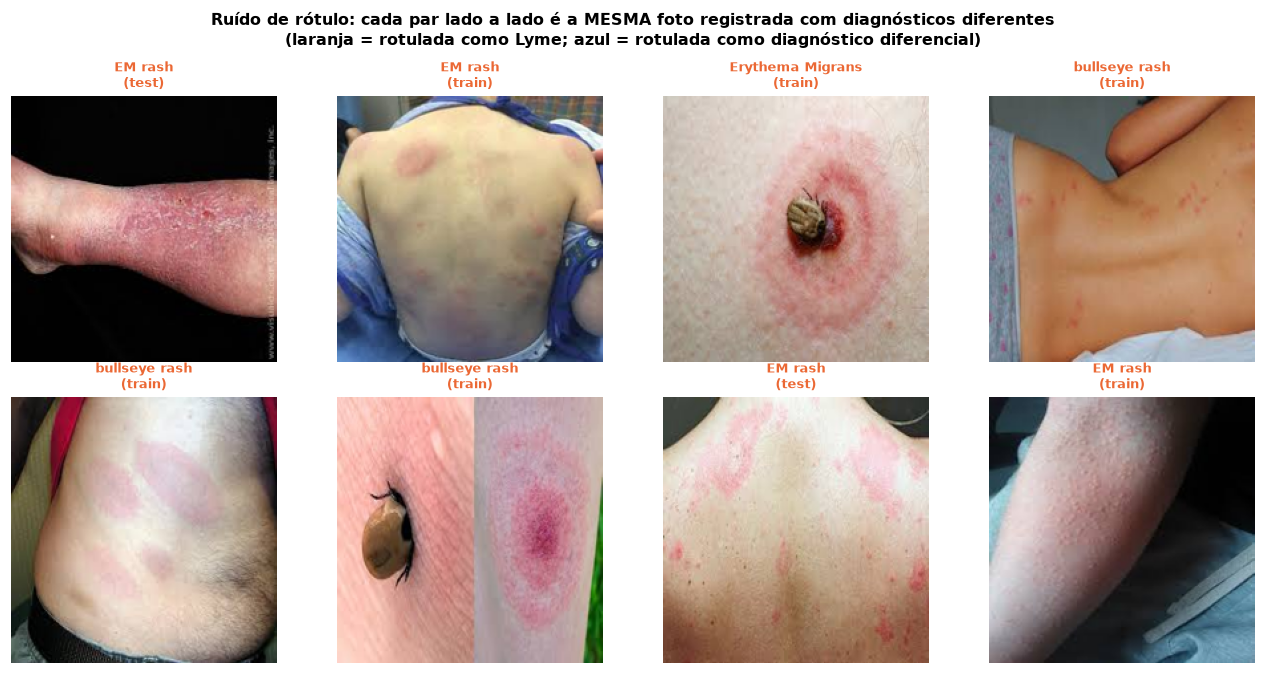

In [9]:
# ---------------------------------------------------------------
# 2.2 Evidencia visual: a mesma fotografia com rotulos clinicos diferentes
# ---------------------------------------------------------------
exemplos = df[df.conflito_rotulo].groupby('grupo_dup').head(2).groupby('grupo_dup').filter(lambda g: len(g) == 2)
exemplos = exemplos.groupby('grupo_dup').head(2).iloc[:8]
fig, eixos = plt.subplots(2, 4, figsize=(12, 6.2))
for ax, (_, linha) in zip(eixos.ravel(), exemplos.iterrows()):
    ax.imshow(Image.open(caminho_imagem(linha)).convert('RGB').resize((200, 200)))
    cor = COR_POS if linha['y'] == 1 else COR_NEG
    ax.set_title(f"{linha['condition']}\n({linha['split']})", fontsize=8.5, color=cor)
    ax.axis('off')
fig.suptitle('Ruído de rótulo: cada par lado a lado é a MESMA foto registrada com diagnósticos diferentes\n'
             '(laranja = rotulada como Lyme; azul = rotulada como diagnóstico diferencial)', fontsize=10.5, fontweight='bold')
plt.tight_layout()
plt.show()

In [10]:
# ---------------------------------------------------------------
# 2.2 Outliers: implausiveis/tecnicos vs extremos patologicos reais
# ---------------------------------------------------------------
def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)

lado_menor = df[['width', 'height']].min(axis=1)
tecnicos = pd.DataFrame({
    'Arquivo corrompido': df['corrupted'],
    'Resolução < 100 px no menor lado': lado_menor < 100,
    'Subexposição (brilho < 66,8)': df['brightness'] < 66.8,
    'Superexposição (brilho > 205,6)': df['brightness'] > 205.6,
    'Pouca pele visível (< 5% dos pixels)': df['skin_fraction'] < 0.05,
})
tab_tec = pd.DataFrame({'n fotos': tecnicos.sum(), '% base': (tecnicos.mean() * 100).round(2),
                        '% entre Lyme': (tecnicos[df.y == 1].mean() * 100).round(2),
                        '% entre controles': (tecnicos[df.y == 0].mean() * 100).round(2)})
print('A) Ruídos técnicos / valores implausíveis de aquisição')
display(tab_tec)

patologicos = ['lab_a_mean', 'a_p90_minus_p50', 'erythema_index', 'saturation_mean', 'radial_a_range', 'glcm_contrast', 'edge_density']
tab_pat = pd.DataFrame({
    'outliers IQR (n)': [outliers_iqr(df[c]).sum() for c in patologicos],
    '% entre Lyme': [outliers_iqr(df[c])[df.y == 1].mean() * 100 for c in patologicos],
    '% entre controles': [outliers_iqr(df[c])[df.y == 0].mean() * 100 for c in patologicos],
    'Mín.': [df[c].min() for c in patologicos], 'Máx.': [df[c].max() for c in patologicos],
}, index=patologicos).round(2)
print('B) Extremos de biomarcadores (regra de Tukey: fora de Q1 − 1,5·IIQ ou Q3 + 1,5·IIQ)')
display(tab_pat)
df['baixa_qualidade'] = tecnicos.drop(columns='Arquivo corrompido').any(axis=1)

A) Ruídos técnicos / valores implausíveis de aquisição


,n fotos,% base,% entre Lyme,% entre controles
Arquivo corrompido,0,0.00,0.00,0.00
Resolução < 100 px no menor lado,4,0.08,0.11,0.07
"Subexposição (brilho < 66,8)",40,0.79,0.74,0.80
"Superexposição (brilho > 205,6)",84,1.66,1.28,1.75
Pouca pele visível (< 5% dos pixels),26,0.51,0.21,0.58


B) Extremos de biomarcadores (regra de Tukey: fora de Q1 − 1,5·IIQ ou Q3 + 1,5·IIQ)


,outliers IQR (n),% entre Lyme,% entre controles,Mín.,Máx.
lab_a_mean,113,1.81,2.33,-25.84,44.69
a_p90_minus_p50,188,4.25,3.59,0.00,64.79
erythema_index,89,1.28,1.87,-77.91,112.44
saturation_mean,63,0.43,1.43,0.00,0.88
radial_a_range,134,3.61,2.43,0.00,59.10
glcm_contrast,311,5.53,6.29,0.10,42.95
edge_density,110,0.74,2.50,0.00,0.14


**Leitura e decisão — outliers e ruídos.**

*Ruído de rótulo e duplicatas (problema mais grave).* A busca por duplicatas com critério duplo (similaridade semântica
dos *embeddings* ≥ 0,95 **e** correlação de pixels ≥ 0,95) encontrou **393 grupos de cópias envolvendo 908 fotos (17,9% da
base)**; **154 grupos cruzam treino/validação/teste** (vazamento: o modelo seria avaliado em fotos que já viu) e **93
grupos (248 fotos) têm rótulos contraditórios** — a mesma imagem aparece como EM e como diagnóstico diferencial. Os pares
mais frequentes (EM em alvo × picada de aranha; EM × eritema marginado; EM × doença do soro-símile) são exatamente os
mimetizadores clínicos do EM, o que indica que as fotos foram coletadas por busca na internet com o termo de cada
doença. **Decisão:** excluir os 248 casos contraditórios (não há verdade-terreno para eles; treinar com eles ensinaria o
modelo a errar) e manter **uma única cópia** de cada grupo (prioridade teste > validação > treino).

*Valores implausíveis/técnicos (A).* Não há arquivos corrompidos; 4 fotos têm resolução < 100 px; 40 estão subexpostas e
84 superexpostas; 26 quase não têm pele visível. São ruídos de aquisição, não de biologia, e **foram mantidos** e
sinalizados (`baixa_qualidade`): um CDSS real receberá fotos de celular mal iluminadas, e excluí-las daria uma estimativa
otimista do desempenho. O Qui-quadrado da Seção 3.A confirma que essas fotos não se associam ao desfecho.

*Extremos patológicos (B).* Valores extremos de vermelhidão (`a_p90_minus_p50`, até 64,8 unidades a*), de amplitude radial
e de textura são **manifestações reais** — eritema intenso de celulite, centro hemorrágico/necrótico de picada de aranha,
anéis muito marcados de EM — e são proporcionalmente **mais frequentes entre os casos de Lyme** em `a_p90_minus_p50`
(4,25% × 3,59%) e `radial_a_range` (3,61% × 2,43%). Excluí-los pela regra de Tukey removeria justamente os EM mais
exuberantes. **Decisão:** manter todos; usar escalonamento robusto (mediana/IIQ) e modelos pouco sensíveis a caudas.

In [11]:
# ---------------------------------------------------------------
# 2.2 Aplicacao das decisoes de limpeza
# ---------------------------------------------------------------
# 1) Remove grupos com rotulo contraditorio (verdade-terreno indefinida)
# 2) Mantem uma unica copia de cada grupo de duplicatas (prioridade teste > validacao > treino),
#    eliminando o vazamento de imagens identicas entre particoes
prioridade = {'test': 0, 'val': 1, 'train': 2}
df_limpo = (df[~df['conflito_rotulo']]
            .assign(_prio=df['split'].map(prioridade))
            .sort_values(['_prio', 'filename'])
            .drop_duplicates('grupo_dup')
            .drop(columns='_prio')
            .sort_index())
IDX_LIMPO = df_limpo.index.values           # posicoes no vetor EMB
EMB_LIMPO = EMB[IDX_LIMPO]
df_limpo = df_limpo.reset_index(drop=True)

auditoria = pd.DataFrame({
    'Etapa': ['Base original', 'Removidas: rótulo contraditório', 'Removidas: cópias redundantes', 'Base analítica final'],
    'Fotos': [len(df), df.conflito_rotulo.sum(), len(df) - df.conflito_rotulo.sum() - len(df_limpo), len(df_limpo)],
})
display(auditoria.style.hide(axis='index'))
display(pd.crosstab(df_limpo['split'], df_limpo['classe'], margins=True, margins_name='Total'))

Etapa,Fotos
Base original,5059
Removidas: rótulo contraditório,248
Removidas: cópias redundantes,360
Base analítica final,4451


classe,Controle (diagnósticos diferenciais),Lyme (eritema migratório),Total
split,,,
test,391,79,470
train,2960,542,3502
val,395,84,479
Total,3746,705,4451


### 2.3 Análise de desbalanceamento de classes

In [12]:
# ---------------------------------------------------------------
# 2.3 Desbalanceamento de classes (antes e depois da limpeza)
# ---------------------------------------------------------------
def resumo_classes(base, nome):
    n_pos, n_neg = base['y'].sum(), (1 - base['y']).sum()
    return {'Base': nome, 'Lyme (n)': n_pos, 'Controles (n)': n_neg, 'Prevalência Lyme': f'{n_pos / len(base):.1%}',
            'Razão Controle:Lyme': f'{n_neg / n_pos:.2f} : 1'}

display(pd.DataFrame([resumo_classes(df, 'Original (5.059)'), resumo_classes(df_limpo, 'Após limpeza')]).style.hide(axis='index'))

Base,Lyme (n),Controles (n),Prevalência Lyme,Razão Controle:Lyme
Original (5.059),941,4118,18.6%,4.38 : 1
Após limpeza,705,3746,15.8%,5.31 : 1


#### Gráfico 1 — Qualidade e proporção da base
Painel A: percentual de valores ausentes por atributo **antes** do tratamento (atributos observados e variáveis
clínicas que a fonte não registra). Painel B: proporção de classes por partição após a limpeza.

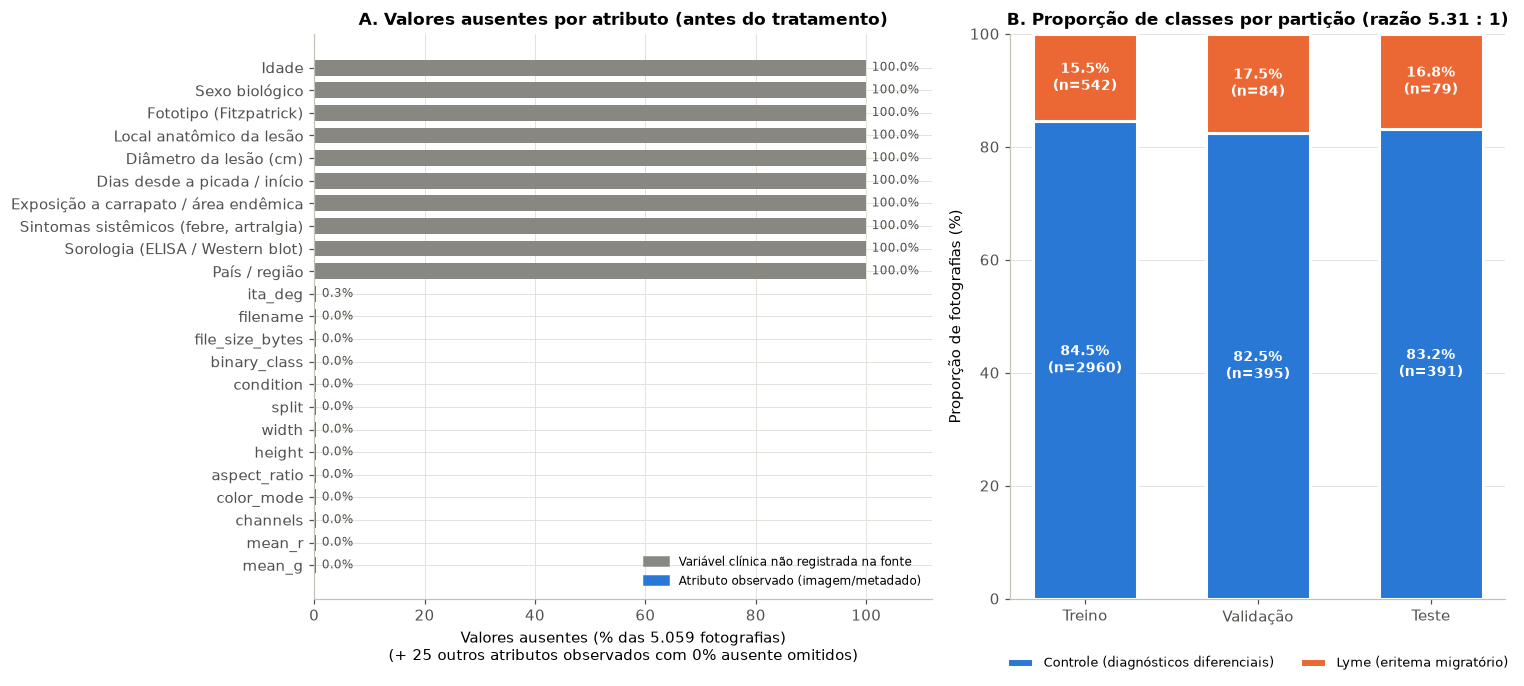

In [13]:
# ---------------------------------------------------------------
# GRAFICO 1 - Valores ausentes por atributo + proporcao de classes
# ---------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.3), gridspec_kw={'width_ratios': [1.25, 1]})

graf = tabela_ausentes.copy()
graf = pd.concat([graf[graf.Origem.str.startswith('Variável')],
                  graf[graf.Origem.str.startswith('Atributo') & (graf['% ausente'] > 0)],
                  graf[graf.Origem.str.startswith('Atributo') & (graf['% ausente'] == 0)].iloc[:12]])
cores = [COR_NEUTRA if o.startswith('Variável') else COR_NEG for o in graf['Origem']]
ax1.barh(graf.index[::-1], graf['% ausente'][::-1].clip(lower=0.4), color=cores[::-1], height=0.7)
for i, v in enumerate(graf['% ausente'][::-1]):
    ax1.text(max(v, 0.4) + 1, i, f'{v:.1f}%', va='center', fontsize=8, color=COR_TEXTO)
ax1.set_xlim(0, 112)
ax1.set_xlabel('Valores ausentes (% das 5.059 fotografias)\n'
               f'(+ {(ausentes_obs == 0).sum() - 12} outros atributos observados com 0% ausente omitidos)')
ax1.set_title('A. Valores ausentes por atributo (antes do tratamento)')
ax1.legend(handles=[mpl.patches.Patch(color=COR_NEUTRA, label='Variável clínica não registrada na fonte'),
                    mpl.patches.Patch(color=COR_NEG, label='Atributo observado (imagem/metadado)')], loc='lower right', fontsize=8)

prop = pd.crosstab(df_limpo['split'], df_limpo['y'], normalize='index').loc[['train', 'val', 'test']] * 100
cont = pd.crosstab(df_limpo['split'], df_limpo['y']).loc[['train', 'val', 'test']]
nomes = ['Treino', 'Validação', 'Teste']
ax2.bar(nomes, prop[0], color=COR_NEG, label=ROTULO[0], width=0.6, edgecolor='white', linewidth=2)
ax2.bar(nomes, prop[1], bottom=prop[0], color=COR_POS, label=ROTULO[1], width=0.6, edgecolor='white', linewidth=2)
for i, s in enumerate(['train', 'val', 'test']):
    ax2.text(i, prop.loc[s, 0] / 2, f'{prop.loc[s, 0]:.1f}%\n(n={cont.loc[s, 0]})', ha='center', va='center', color='white', fontsize=9, fontweight='bold')
    ax2.text(i, prop.loc[s, 0] + prop.loc[s, 1] / 2, f'{prop.loc[s, 1]:.1f}%\n(n={cont.loc[s, 1]})', ha='center', va='center', color='white', fontsize=9, fontweight='bold')
ax2.set_ylabel('Proporção de fotografias (%)')
ax2.set_ylim(0, 100)
ax2.set_title(f'B. Proporção de classes por partição (razão {(1 - df_limpo.y).sum() / df_limpo.y.sum():.2f} : 1)')
ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=8.5)
ax2.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

**Leitura técnica e clínica do Gráfico 1.**
(A) Os atributos de imagem são praticamente completos (apenas `ita_deg` com 0,3% ausente), mas as barras cinza mostram o
verdadeiro problema de qualidade: **nenhuma variável clínica do paciente foi registrada**. Na prática, o modelo terá de
diagnosticar só pela foto, sem a anamnese que mais pesa no diagnóstico de EM (picada de carrapato, viagem a área endêmica,
evolução em dias). (B) Após a limpeza, a prevalência de Lyme caiu de 18,6% para **15,8% (razão 5,31 controles : 1 caso)**
porque todo grupo com rótulo contraditório continha ao menos uma foto registrada como EM. A proporção é semelhante nas três
partições (15,5%, 17,5% e 16,8%; Qui-quadrado p = 0,43), ou seja, a estratificação original foi preservada. Com esse
desbalanceamento, um classificador que responda sempre "controle" acerta 84% — ponto retomado na Seção 3.B.

#### Estratégias de mitigação do desbalanceamento
O desbalanceamento de 5,3 : 1 é tratado em três frentes, comparadas empiricamente na Seção 3.B.1: **ponderação de classes**
(`class_weight='balanced'`, que multiplica o custo de errar um caso de Lyme por ≈ 5,3), **subamostragem dos controles**
(*undersampling*, aplicada apenas dentro dos *folds* de treino) e **ajuste do limiar de decisão** (Seção 4). O SMOTE não foi
usado: interpolar *embeddings* de duas fotos não gera uma lesão clinicamente plausível e, em imagens, a forma correta de
sobreamostrar seria a aumentação de dados (rotação, recorte, brilho), que exige re-treinar a CNN.

### 2.4 Padronização e codificação

In [14]:
# ---------------------------------------------------------------
# 2.4 Padronizacao e codificacao
# ---------------------------------------------------------------
# Assimetria (skewness) justifica o RobustScaler (mediana e IIQ) nos biomarcadores
assimetria = df_limpo[BIOMARCADORES].skew().sort_values(key=np.abs, ascending=False).round(2)
print('Biomarcadores mais assimétricos (|skew| > 1 indica cauda longa):')
print(assimetria.head(8).to_string())

dev_mask = df_limpo['split'].isin(['train', 'val']).values
demo = RobustScaler().fit(df_limpo.loc[dev_mask, BIOMARCADORES])   # ajuste APENAS no conjunto de desenvolvimento
escalado = pd.DataFrame(demo.transform(df_limpo[BIOMARCADORES]), columns=BIOMARCADORES)
cols_demo = ['lab_a_mean', 'a_p90_minus_p50', 'glcm_contrast', 'edge_density']
antes_depois = pd.concat({'Antes (unidade original)': df_limpo[cols_demo].describe().loc[['50%', 'mean', 'std', 'min', 'max']],
                          'Depois (RobustScaler)': escalado[cols_demo].describe().loc[['50%', 'mean', 'std', 'min', 'max']]})
display(antes_depois.round(3))

# Codificacao das variaveis categoricas clinicas
df_limpo['grupo_tom_pele'] = pd.cut(df_limpo['ita_deg'], [-90, 10, 41, 90],
                                    labels=['Escura ou sombreada (ITA ≤ 10°)', 'Intermediária (10°–41°)', 'Clara (ITA > 41°)'])
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore').fit(df_limpo[['condition']])
condicao_ohe = pd.DataFrame(ohe.transform(df_limpo[['condition']]), columns=ohe.get_feature_names_out())
print(f"Desfecho codificado: y = 1 (Lyme) / 0 (controle). Condição clínica -> {condicao_ohe.shape[1]} colunas one-hot. "
      f"Tom de pele -> 3 categorias ordinais (ITA).")
display(condicao_ohe.iloc[:3, :6])

Biomarcadores mais assimétricos (|skew| > 1 indica cauda longa):
glcm_contrast       3.05
glcm_correlation   -2.77
sharpness_lap       2.51
glcm_energy         2.21
gray_entropy       -1.86
a_p90_minus_p50     1.72
radial_a_range      1.43
a_std               1.36


lab_a_mean  a_p90_minus_p50  glcm_contrast  edge_density
Antes (unidade original) 50%       11.172            8.712          2.340         0.022
                         mean      11.776           10.153          3.320         0.026
                         std        7.458            6.384          3.328         0.019
                         min      -25.835            0.000          0.100         0.000
                         max       44.691           64.792         42.954         0.144
Depois (RobustScaler)    50%       -0.002            0.000         -0.003        -0.002
                         mean       0.062            0.198          0.323         0.150
                         std        0.797            0.876          1.106         0.762
                         min       -3.958           -1.196         -0.747        -0.861
                         max        3.581            7.698         13.487         4.842

Desfecho codificado: y = 1 (Lyme) / 0 (controle). Condição clínica -> 15 colunas one-hot. Tom de pele -> 3 categorias ordinais (ITA).


,condition_Bacterial cellulitis,condition_EM rash,condition_Erythema Migrans,condition_Erythema marginatum,condition_Fixed drug eruption,condition_Local reaction to arthropod bite
0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0


**Leitura e decisão — padronização e codificação.** Oito biomarcadores têm |assimetria| > 1 (ex.: contraste GLCM 3,05;
nitidez 2,51; contraste eritematoso 1,72). Para eles foi escolhido o **RobustScaler**, que centraliza pela mediana e divide
pelo IIQ: os valores típicos ficam em torno de 0 (mediana ≈ 0 após a transformação) sem que os extremos patológicos mantidos
na Seção 2.2 dominem a escala — com o StandardScaler, média e desvio seriam puxados pelas caudas. Os *embeddings* da CNN,
aproximadamente simétricos, recebem **StandardScaler** (exigido pela regressão logística regularizada). Todos os
escalonadores são ajustados **somente no desenvolvimento** e embutidos em *pipelines*, de modo que, dentro da validação
cruzada, cada *fold* é escalonado apenas com os próprios dados de treino. Codificação: desfecho binário (`y` = 1 Lyme),
condição clínica em *one-hot* (15 colunas, usada apenas na descrição dos clusters — nunca como preditor, pois é o próprio
diagnóstico) e tom de pele em 3 categorias ordinais de ITA.

## Seção 03 — Métricas estatísticas, análise exploratória e modelagem

### 3.A Métricas descritivas e inferenciais (biomarcadores × desfecho)
Para cada biomarcador comparamos Lyme × controles com **média ± desvio-padrão** e **mediana [IIQ]** (a mediana é a medida
robusta, dada a assimetria de vários atributos). A significância é avaliada pelo **teste de Mann-Whitney** (não paramétrico,
adequado a distribuições assimétricas) e, como referência, pelo **teste t de Welch**. Como são 14 testes simultâneos,
os p-valores são corrigidos por **Benjamini-Hochberg** (q-valor) e o tamanho de efeito é dado pelo **δ de Cliff**
(|δ| < 0,147 desprezível; < 0,33 pequeno; < 0,474 médio; ≥ 0,474 grande). Com ~4.400 fotos, p-valores minúsculos
aparecem mesmo para diferenças clinicamente irrelevantes — por isso o tamanho de efeito é o critério principal.

In [15]:
# ---------------------------------------------------------------
# 3.A Tendencia central, dispersao e testes de hipotese por grupo
# ---------------------------------------------------------------
CHAVE = ['lab_a_mean', 'a_p90_minus_p50', 'erythema_index', 'a_std', 'saturation_mean', 'radial_a_center_minus_mid',
         'radial_a_range', 'glcm_contrast', 'glcm_homogeneity', 'gray_entropy', 'edge_density', 'sharpness_lap',
         'ita_deg_imput', 'brightness']

def cliff_delta(x, y):
    """Tamanho de efeito nao parametrico: P(X>Y) - P(X<Y), a partir da estatistica U."""
    u = stats.mannwhitneyu(x, y).statistic
    return 2 * u / (len(x) * len(y)) - 1

linhas = []
for c in CHAVE:
    pos, neg = df_limpo.loc[df_limpo.y == 1, c], df_limpo.loc[df_limpo.y == 0, c]
    linhas.append({'Biomarcador': c,
                   'Lyme média ± DP': f'{pos.mean():.2f} ± {pos.std():.2f}',
                   'Lyme mediana [IIQ]': f'{pos.median():.2f} [{pos.quantile(.25):.2f}; {pos.quantile(.75):.2f}]',
                   'Controle média ± DP': f'{neg.mean():.2f} ± {neg.std():.2f}',
                   'Controle mediana [IIQ]': f'{neg.median():.2f} [{neg.quantile(.25):.2f}; {neg.quantile(.75):.2f}]',
                   'Assimetria': round(df_limpo[c].skew(), 2),
                   'p (Mann-Whitney)': stats.mannwhitneyu(pos, neg).pvalue,
                   'p (t de Welch)': stats.ttest_ind(pos, neg, equal_var=False).pvalue,
                   "δ de Cliff": cliff_delta(pos, neg)})
tab_desc = pd.DataFrame(linhas)
# Correcao de Benjamini-Hochberg para comparacoes multiplas
ordem = tab_desc['p (Mann-Whitney)'].rank(method='first').values
m = len(tab_desc)
q = (tab_desc['p (Mann-Whitney)'] * m / ordem).values
q_ord = np.minimum.accumulate(q[np.argsort(ordem)[::-1]])[::-1]
tab_desc['q (BH)'] = np.clip(q_ord[np.argsort(np.argsort(ordem))], 0, 1)
tab_desc['Significativo (q < 0,05)'] = np.where(tab_desc['q (BH)'] < 0.05, 'Sim', 'Não')
tab_desc = tab_desc.sort_values("δ de Cliff", key=np.abs, ascending=False).reset_index(drop=True)
display(tab_desc.style.format({'Assimetria': '{:.2f}', 'p (Mann-Whitney)': '{:.1e}', 'p (t de Welch)': '{:.1e}', 'q (BH)': '{:.1e}', "δ de Cliff": '{:+.3f}'}).hide(axis='index'))

Biomarcador,Lyme média ± DP,Lyme mediana [IIQ],Controle média ± DP,Controle mediana [IIQ],Assimetria,p (Mann-Whitney),p (t de Welch),δ de Cliff,q (BH),"Significativo (q < 0,05)"
radial_a_range,11.58 ± 7.29,10.02 [6.23; 15.68],9.70 ± 7.02,8.22 [4.46; 13.13],1.43,3.7e-13,4.2e-10,+0.172,5.2e-12,Sim
radial_a_center_minus_mid,3.53 ± 7.00,2.86 [-0.62; 7.57],2.08 ± 6.19,1.36 [-1.18; 5.26],0.47,8.9e-09,3.9e-07,+0.136,6.2e-08,Sim
glcm_homogeneity,0.76 ± 0.09,0.77 [0.71; 0.83],0.74 ± 0.10,0.75 [0.68; 0.81],-0.83,3.1e-07,1.4e-07,+0.121,1.4e-06,Sim
a_p90_minus_p50,10.91 ± 6.21,9.89 [6.67; 13.45],10.01 ± 6.41,8.52 [5.53; 12.84],1.72,1.7e-06,4.9e-04,+0.113,5.9e-06,Sim
sharpness_lap,9.86 ± 7.36,7.65 [4.97; 12.40],10.74 ± 7.82,8.78 [5.65; 13.18],2.51,9.7e-05,4.3e-03,-0.092,2.7e-04,Sim
ita_deg_imput,30.96 ± 35.71,37.09 [11.90; 56.63],26.50 ± 38.22,33.08 [4.64; 55.53],-0.78,1.1e-02,2.7e-03,+0.061,2.5e-02,Sim
a_std,8.31 ± 3.72,7.78 [5.82; 9.89],8.02 ± 3.81,7.52 [5.29; 9.97],1.36,2.1e-02,5.7e-02,+0.055,4.3e-02,Sim
brightness,140.76 ± 29.52,139.64 [123.42; 159.80],138.51 ± 31.27,137.71 [117.07; 159.28],0.07,4.0e-02,6.6e-02,+0.049,7.0e-02,Não
gray_entropy,6.94 ± 0.63,7.09 [6.65; 7.37],6.91 ± 0.61,7.04 [6.61; 7.35],-1.86,1.1e-01,2.7e-01,+0.038,1.5e-01,Não
edge_density,0.02 ± 0.02,0.02 [0.01; 0.04],0.03 ± 0.02,0.02 [0.01; 0.04],1.07,1.1e-01,8.3e-02,-0.038,1.5e-01,Não


**Interpretação clínica das métricas descritivas e inferenciais.**
- **Sete biomarcadores diferem significativamente** entre Lyme e controles após a correção de Benjamini-Hochberg, mas
  **todos com efeito desprezível a pequeno** (|δ| ≤ 0,17). Os mais fortes são os ligados ao **padrão radial**: a amplitude
  radial da vermelhidão (mediana 10,0 × 8,2; δ = +0,17) e a diferença centro − anel intermediário (2,9 × 1,4; δ = +0,14),
  coerentes com a lesão centrada e anelar do EM. Seguem a **homogeneidade da textura** (EM é uma mácula lisa, sem
  descamação ou vesículas; δ = +0,12) e o **contraste eritematoso** (δ = +0,11).
- A **vermelhidão média** (a*, índice R − G) e a saturação **não diferem** (q > 0,15): confirma, com teste formal, a
  conclusão da Entrega 01 de que "estar vermelho" não distingue EM de celulite, urticária ou picada.
- Mediana e IIQ foram reportados ao lado de média ± DP porque vários marcadores são assimétricos (ex.: nitidez, assimetria
  2,51); Mann-Whitney e t de Welch concordam na significância, exceto `a_std` e brilho, que ficam no limiar.
- **Conclusão para a pergunta de classificação:** nenhum biomarcador isolado serve como teste diagnóstico — a separação
  precisa vir da **combinação multivariada** de forma, padrão espacial e textura, o que justifica o uso de modelos.

#### Gráfico 2 — Distribuição comparativa dos biomarcadores-chave (Lyme × controles)
Os seis biomarcadores com maior tamanho de efeito (|δ de Cliff|) são exibidos em *violin plots* com *boxplot* interno
(mediana = linha branca; caixa = IIQ). Os pontos além dos bigodes são os extremos patológicos mantidos na base.

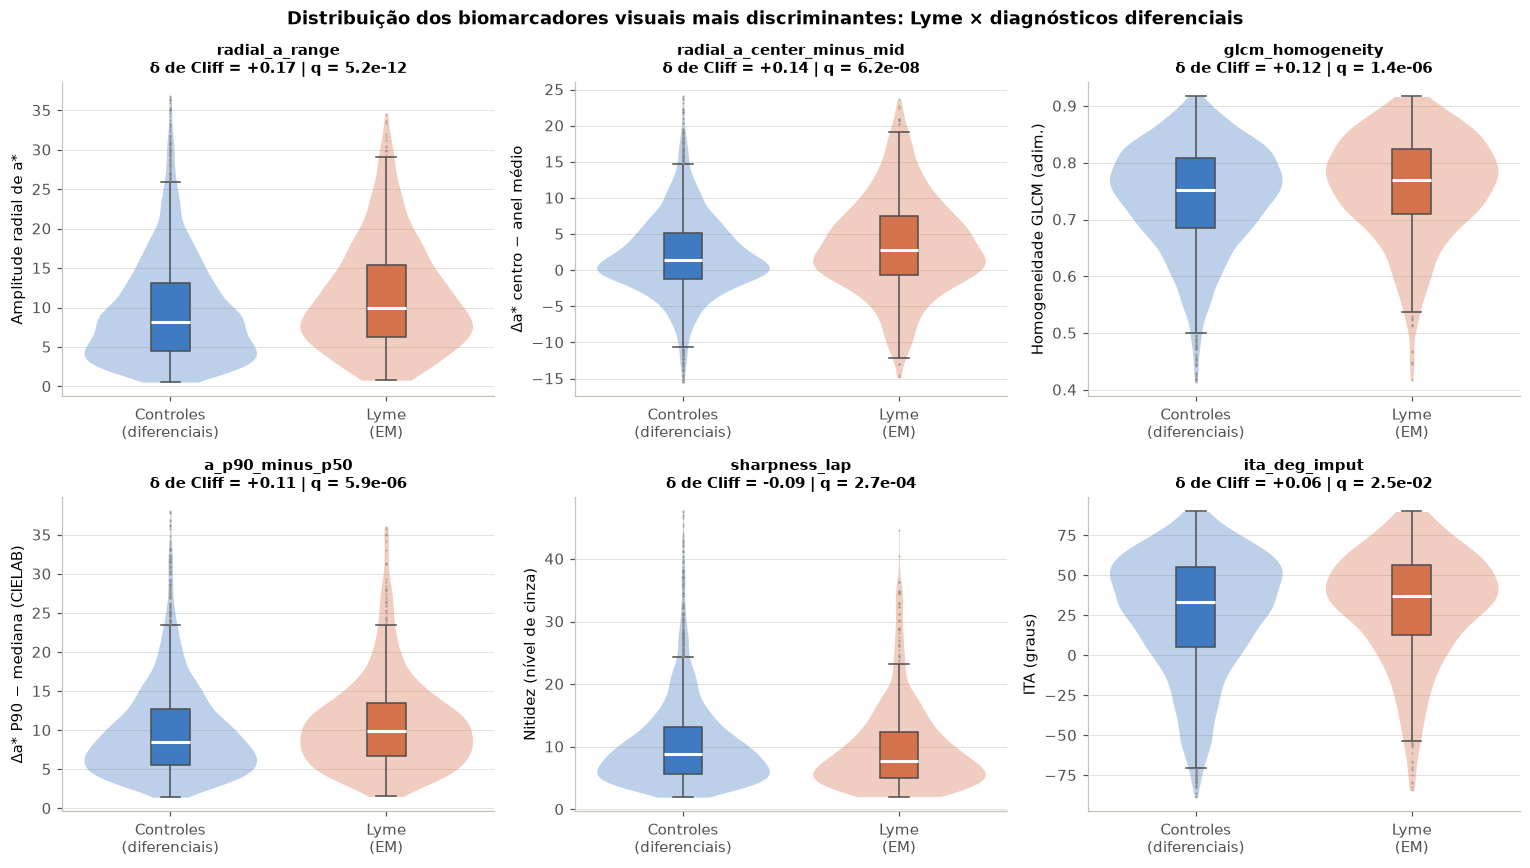

In [16]:
# ---------------------------------------------------------------
# GRAFICO 2 - Violin + boxplot dos 6 biomarcadores mais discriminantes
# ---------------------------------------------------------------
UNIDADES = {'lab_a_mean': 'a* médio (CIELAB)', 'a_p90_minus_p50': 'Δa* P90 − mediana (CIELAB)', 'erythema_index': 'R − G (0–255)',
            'a_std': 'DP de a* (CIELAB)', 'saturation_mean': 'Saturação HSV (0–1)', 'radial_a_center_minus_mid': 'Δa* centro − anel médio',
            'radial_a_range': 'Amplitude radial de a*', 'glcm_contrast': 'Contraste GLCM (adim.)', 'glcm_homogeneity': 'Homogeneidade GLCM (adim.)',
            'gray_entropy': 'Entropia (bits)', 'edge_density': 'Densidade de bordas (fração)', 'sharpness_lap': 'Nitidez (nível de cinza)',
            'ita_deg_imput': 'ITA (graus)', 'brightness': 'Luminância (0–255)'}
top6 = tab_desc['Biomarcador'].iloc[:6].tolist()
fig, eixos = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(eixos.ravel(), top6):
    lim = df_limpo[c].quantile([0.005, 0.995]).values
    dados = df_limpo[df_limpo[c].between(*lim)]
    sns.violinplot(data=dados, x='classe', y=c, hue='classe', palette=PALETA_CLASSE, order=[ROTULO[0], ROTULO[1]],
                   inner=None, cut=0, linewidth=0, ax=ax, legend=False)
    for col in ax.collections:
        col.set_alpha(0.35)
    sns.boxplot(data=dados, x='classe', y=c, hue='classe', palette=PALETA_CLASSE, order=[ROTULO[0], ROTULO[1]], width=0.18,
                fliersize=1.5, linewidth=1, ax=ax, legend=False, medianprops={'color': 'white', 'linewidth': 2},
                flierprops={'marker': 'o', 'markerfacecolor': COR_NEUTRA, 'markeredgecolor': 'none', 'alpha': 0.5})
    linha = tab_desc.set_index('Biomarcador').loc[c]
    ax.set_title(f"{c}\nδ de Cliff = {linha['δ de Cliff']:+.2f} | q = {linha['q (BH)']:.1e}", fontsize=9.5)
    ax.set_xlabel('')
    ax.set_ylabel(UNIDADES[c])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Controles\n(diferenciais)', 'Lyme\n(EM)'])
fig.suptitle('Distribuição dos biomarcadores visuais mais discriminantes: Lyme × diagnósticos diferenciais', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Leitura técnica e clínica do Gráfico 2.** As distribuições de Lyme (laranja) e controles (azul) **se sobrepõem quase
totalmente**; o deslocamento das medianas é pequeno e consistente com os δ de Cliff da tabela. O EM tende a maior
amplitude radial e maior vermelhidão no centro em relação ao anel intermediário (painéis 1 e 2), o que corresponde ao
"alvo" e à lesão centrada na picada — porém muitos controles (picadas de aranha, reação a artrópode, eritema anular) também
são anelares, por isso a sobreposição. O EM é mais **homogêneo e menos "nítido"** em textura (painéis 3 e 5): mácula lisa,
sem as escamas da tinea ou as vesículas do herpes-zóster. As caudas longas (pontos) foram mantidas por serem extremos
patológicos reais. **Implicação clínica:** um limiar em qualquer um desses biomarcadores isolados geraria muitos falsos
positivos; eles são úteis como **sinais de apoio** combinados, não como critério único.

#### Gráfico 3 — Mapa de calor de correlação de Spearman entre biomarcadores
Spearman foi escolhido (em vez de Pearson) porque vários biomarcadores são assimétricos e as relações esperadas são
monotônicas, não necessariamente lineares. A última linha mostra a correlação ponto-bisserial de cada biomarcador com o desfecho.

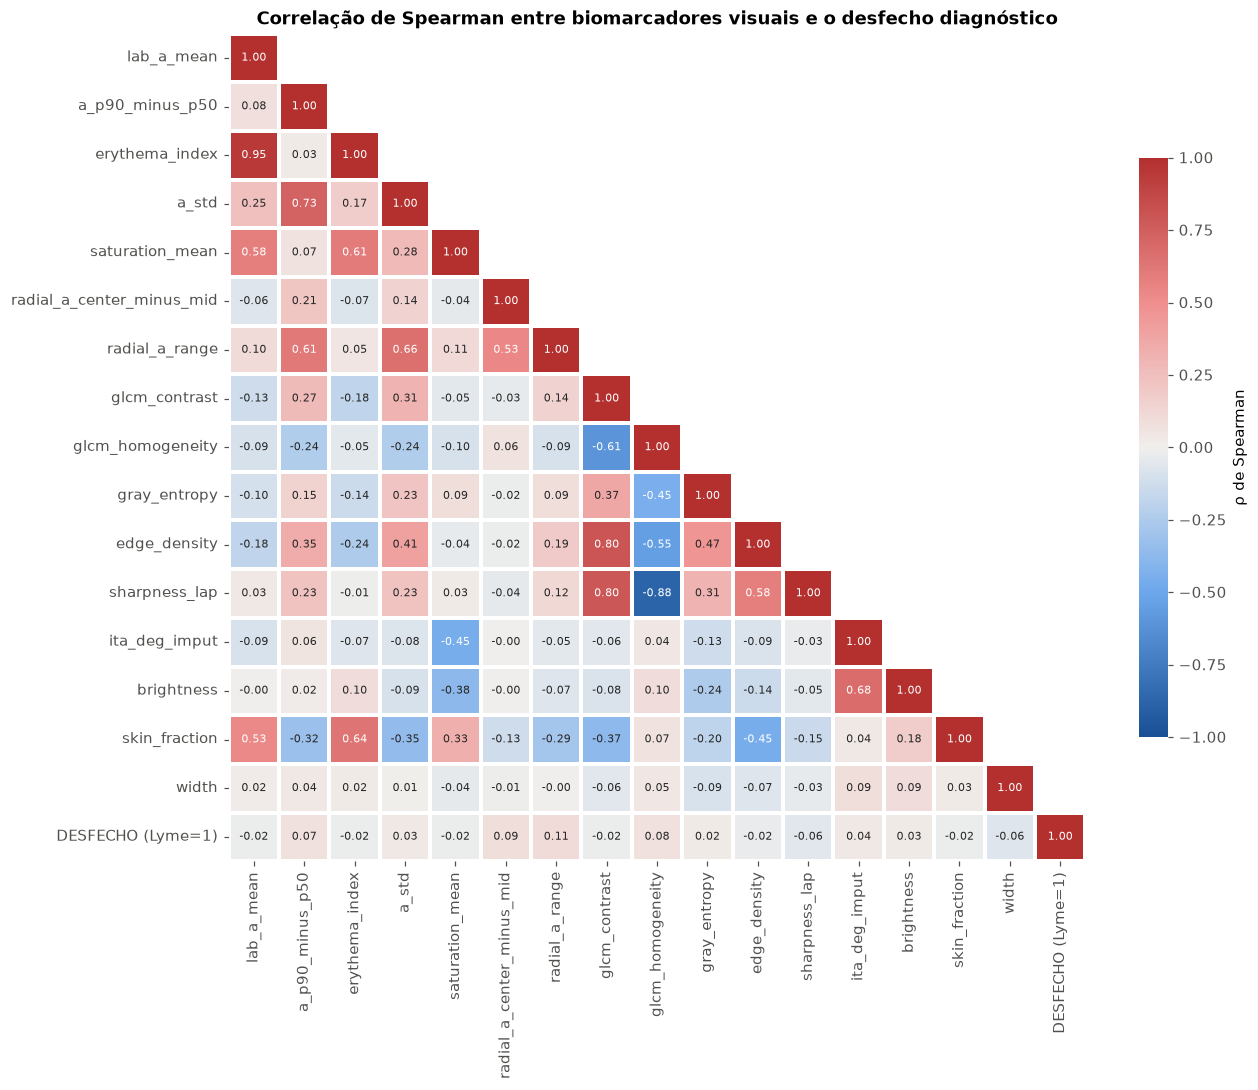

Pares mais redundantes (|ρ| mais alto):
       level_0          level_1       rho
erythema_index       lab_a_mean  0.946878
 sharpness_lap glcm_homogeneity -0.880102
  edge_density    glcm_contrast  0.803585
 sharpness_lap    glcm_contrast  0.795506
         a_std  a_p90_minus_p50  0.729272
    brightness    ita_deg_imput  0.675056


In [17]:
# ---------------------------------------------------------------
# GRAFICO 3 - Heatmap de correlacao de Spearman
# ---------------------------------------------------------------
cols_corr = CHAVE + ['skin_fraction', 'width']
corr = df_limpo[cols_corr + ['y']].corr(method='spearman')
corr = corr.rename(index={'y': 'DESFECHO (Lyme=1)'}, columns={'y': 'DESFECHO (Lyme=1)'})
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=mascara, cmap=CMAP_DIV, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f', annot_kws={'size': 7},
            linewidths=1.5, linecolor='white', cbar_kws={'label': 'ρ de Spearman', 'shrink': 0.7}, ax=ax)
ax.set_title('Correlação de Spearman entre biomarcadores visuais e o desfecho diagnóstico', fontsize=12)
ax.grid(False)
plt.tight_layout()
plt.show()

pares_red = (corr.where(~mascara).stack().reset_index().rename(columns={0: 'rho'}))
pares_red = pares_red[(pares_red.level_0 != pares_red.level_1)].sort_values('rho', key=np.abs, ascending=False)
print('Pares mais redundantes (|ρ| mais alto):')
print(pares_red.head(6).to_string(index=False))

**Leitura técnica e clínica do Gráfico 3.**
- **Redundâncias:** `erythema_index` (R − G) e `lab_a_mean` (a*) medem a mesma coisa (ρ = 0,95) — basta um deles; nitidez,
  contraste GLCM e densidade de bordas formam um bloco de "textura/irregularidade" (|ρ| entre 0,80 e 0,88); o contraste
  eritematoso e o desvio de a* (ρ = 0,73) medem heterogeneidade da vermelhidão.
- **Confundidor de aquisição:** o ITA correlaciona-se fortemente com o **brilho da foto** (ρ = 0,68) — sinal de que o
  "tom de pele" estimado mistura fototipo com iluminação, o que é investigado na Seção 5.
- **Sinergias diagnósticas:** a linha DESFECHO mostra que **nenhum** biomarcador tem |ρ| > 0,11 com o diagnóstico; os de
  maior associação (amplitude radial 0,11; centro − anel 0,09; homogeneidade 0,08) são quase independentes da vermelhidão
  média (ρ ≈ 0,1), ou seja, **padrão espacial e cor carregam informações complementares** — combinação explorada pelos modelos.
- A largura da imagem (atributo de aquisição) não se associa ao desfecho (ρ = −0,06), o que reduz a preocupação de que o
  modelo aprenda o "site de origem" pela resolução.

In [18]:
# ---------------------------------------------------------------
# 3.A Tabelas de contingencia + Qui-quadrado (associacao categorica)
# ---------------------------------------------------------------
def qui_quadrado(var, titulo):
    tab = pd.crosstab(df_limpo[var], df_limpo['classe'])
    chi2, p, gl, _ = stats.chi2_contingency(tab)
    v_cramer = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    tab_pct = pd.crosstab(df_limpo[var], df_limpo['classe'], normalize='index').mul(100).round(1).add_suffix(' (% linha)')
    print(f'{titulo}: χ² = {chi2:.2f}, gl = {gl}, p = {p:.2e}, V de Cramér = {v_cramer:.3f}')
    display(pd.concat([tab, tab_pct], axis=1))

qui_quadrado('split', '1) Partição × desfecho (a estratificação foi preservada após a limpeza?)')
qui_quadrado('grupo_tom_pele', '2) Tom de pele (ITA) × desfecho')
qui_quadrado('baixa_qualidade', '3) Foto de baixa qualidade técnica × desfecho')

1) Partição × desfecho (a estratificação foi preservada após a limpeza?): χ² = 1.71, gl = 2, p = 4.25e-01, V de Cramér = 0.020


classe,Controle (diagnósticos diferenciais),Lyme (eritema migratório),Controle (diagnósticos diferenciais) (% linha),Lyme (eritema migratório) (% linha)
split,,,,
test,391,79,83.2,16.8
train,2960,542,84.5,15.5
val,395,84,82.5,17.5


2) Tom de pele (ITA) × desfecho: χ² = 10.31, gl = 2, p = 5.77e-03, V de Cramér = 0.048


classe,Controle (diagnósticos diferenciais),Lyme (eritema migratório),Controle (diagnósticos diferenciais) (% linha),Lyme (eritema migratório) (% linha)
grupo_tom_pele,,,,
Escura ou sombreada (ITA ≤ 10°),1087,164,86.9,13.1
Intermediária (10°–41°),1077,226,82.7,17.3
Clara (ITA > 41°),1567,315,83.3,16.7


3) Foto de baixa qualidade técnica × desfecho: χ² = 0.81, gl = 1, p = 3.69e-01, V de Cramér = 0.013


classe,Controle (diagnósticos diferenciais),Lyme (eritema migratório),Controle (diagnósticos diferenciais) (% linha),Lyme (eritema migratório) (% linha)
baixa_qualidade,,,,
False,3623,687,84.1,15.9
True,123,18,87.2,12.8


**Interpretação dos testes Qui-quadrado.** (1) A proporção de Lyme não difere entre treino, validação e teste após a
limpeza (p = 0,43; V = 0,02): a avaliação no teste é representativa. (2) Há associação estatisticamente significativa,
mas muito fraca, entre tom de pele aparente e desfecho (χ² = 10,3; p = 0,006; V de Cramér = 0,048): fotos "escuras ou
sombreadas" têm menor proporção de Lyme (13,1% × 17,3% e 16,7%) — o que reflete a sub-representação de EM em pele
pigmentada na literatura e nos atlas de onde as fotos foram coletadas. (3) A baixa qualidade técnica não se associa ao
desfecho (p = 0,37), justificando mantê-las sem viés de classe.

### 3.B Métricas de desempenho analítico e modelagem

#### 3.B.1 Diagnóstico diferencial (classificação supervisionada) — Pergunta 02
**Desenho experimental.** O conjunto de **teste** oficial (após deduplicação) fica intocado até a avaliação final. No
conjunto de **desenvolvimento** (treino + validação) usamos **validação cruzada estratificada de 5 *folds***: ela escolhe
hiperparâmetros e gera probabilidades *fora-do-fold* (nunca vistas pelo modelo) que servem para definir os limiares do CDSS
sem tocar no teste.

Três abordagens são comparadas com uma **linha de base** que sempre responde "controle":
- **A) Biomarcadores interpretáveis + Gradient Boosting** — modelo explicável, que permite SHAP por biomarcador;
- **B) *Embeddings* da CNN + Regressão Logística** — *transfer learning* (sonda linear sobre ConvNeXt-Tiny/ImageNet);
- **C) Fusão A + B** — média das probabilidades (combina forma/padrão espacial da CNN com cor/textura dos biomarcadores).

Métricas obrigatórias: matriz de confusão, **sensibilidade** (recall), **especificidade**, **VPP** (precisão), **VPN**,
**F1**, **AUC-ROC** e **AUC-PR**. Em base desbalanceada a AUC-PR é a métrica de seleção: sua linha de base é a
prevalência (~18%), enquanto a da AUC-ROC é sempre 0,5.

In [19]:
# ---------------------------------------------------------------
# 3.B.1 Conjuntos de desenvolvimento (treino+validacao) e teste
# ---------------------------------------------------------------
dev = df_limpo[dev_mask].reset_index(drop=True)
teste = df_limpo[~dev_mask].reset_index(drop=True)
X_bio_dev, X_bio_te = dev[BIOMARCADORES].values, teste[BIOMARCADORES].values
X_emb_dev, X_emb_te = EMB_LIMPO[dev_mask], EMB_LIMPO[~dev_mask]
y_dev, y_te = dev['y'].values, teste['y'].values
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f'Desenvolvimento: {len(dev)} fotos ({y_dev.sum()} Lyme) | Teste (nunca usado no ajuste): {len(teste)} fotos ({y_te.sum()} Lyme)')

def metricas(y, p, limiar=0.5):
    pred = (p >= limiar).astype(int)
    vn, fp, fn, vp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'Sensibilidade': vp / (vp + fn), 'Especificidade': vn / (vn + fp),
            'VPP (precisão)': vp / (vp + fp) if vp + fp else np.nan, 'VPN': vn / (vn + fn) if vn + fn else np.nan,
            'F1-Score': f1_score(y, pred, zero_division=0), 'Acurácia': (vp + vn) / len(y),
            'Acurácia balanceada': (vp / (vp + fn) + vn / (vn + fp)) / 2,
            'AUC-ROC': roc_auc_score(y, p), 'AUC-PR': average_precision_score(y, p),
            'VP': vp, 'FN': fn, 'FP': fp, 'VN': vn}

def ic_bootstrap(y, p, limiar, n=1000, seed=RANDOM_STATE):
    """IC 95% por bootstrap estratificado (reamostra Lyme e controles separadamente)."""
    rng = np.random.default_rng(seed)
    ip, ineg = np.where(y == 1)[0], np.where(y == 0)[0]
    amostras = []
    for _ in range(n):
        idx = np.concatenate([rng.choice(ip, len(ip)), rng.choice(ineg, len(ineg))])
        amostras.append(metricas(y[idx], p[idx], limiar))
    a = pd.DataFrame(amostras)
    return a.quantile(0.025), a.quantile(0.975)

Desenvolvimento: 3981 fotos (626 Lyme) | Teste (nunca usado no ajuste): 470 fotos (79 Lyme)


In [20]:
# ---------------------------------------------------------------
# 3.B.1 Modelos candidatos avaliados por validacao cruzada (5 folds)
# ---------------------------------------------------------------
def modelo_biomarcadores():
    # Imputacao pela mediana + indicador de ausencia (ITA), escala robusta e gradient boosting balanceado
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True), RobustScaler(),
                         HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                                                        l2_regularization=1.0, class_weight='balanced',
                                                        random_state=RANDOM_STATE))

def modelo_embeddings(C=0.003, class_weight='balanced'):
    # Transfer learning: sonda linear (regressao logistica regularizada) sobre os embeddings da CNN
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000, class_weight=class_weight))

# Ajuste da regularizacao C da sonda linear por validacao cruzada (criterio: AUC-PR)
busca_C = {C: average_precision_score(y_dev, cross_val_predict(modelo_embeddings(C), X_emb_dev, y_dev, cv=CV,
                                                               method='predict_proba')[:, 1])
           for C in [0.0005, 0.001, 0.003, 0.01, 0.03]}
C_OTIMO = max(busca_C, key=busca_C.get)
print('AUC-PR em validação cruzada por valor de C:', {k: round(v, 3) for k, v in busca_C.items()}, '-> C escolhido =', C_OTIMO)

oof = {
    'Linha de base (classe majoritária)': cross_val_predict(DummyClassifier(strategy='prior'), X_bio_dev, y_dev, cv=CV, method='predict_proba')[:, 1],
    'A) Biomarcadores + GB': cross_val_predict(modelo_biomarcadores(), X_bio_dev, y_dev, cv=CV, method='predict_proba')[:, 1],
    'B) Embeddings CNN + RL': cross_val_predict(modelo_embeddings(C_OTIMO), X_emb_dev, y_dev, cv=CV, method='predict_proba')[:, 1],
}
oof['C) Fusão A + B'] = (oof['A) Biomarcadores + GB'] + oof['B) Embeddings CNN + RL']) / 2

tab_cv = pd.DataFrame({nome: metricas(y_dev, p) for nome, p in oof.items()}).T
# Criterio de selecao do modelo final definido a priori: maior AUC-PR na validacao cruzada
NOME_FINAL = tab_cv.drop(index='Linha de base (classe majoritária)')['AUC-PR'].idxmax()
print(f'Modelo selecionado para o CDSS (maior AUC-PR em validação cruzada): {NOME_FINAL}')
display(tab_cv[['AUC-ROC', 'AUC-PR', 'Sensibilidade', 'Especificidade', 'VPP (precisão)', 'F1-Score', 'Acurácia', 'Acurácia balanceada']]
        .style.format('{:.3f}').highlight_max(subset=['AUC-ROC', 'AUC-PR'], color='#cde2fb'))

AUC-PR em validação cruzada por valor de C: {0.0005: 0.433, 0.001: 0.445, 0.003: 0.449, 0.01: 0.435, 0.03: 0.409} -> C escolhido = 0.003


Modelo selecionado para o CDSS (maior AUC-PR em validação cruzada): B) Embeddings CNN + RL


,AUC-ROC,AUC-PR,Sensibilidade,Especificidade,VPP (precisão),F1-Score,Acurácia,Acurácia balanceada
Linha de base (classe majoritária),0.499,0.157,0.000,1.000,nan,0.000,0.843,0.500
A) Biomarcadores + GB,0.625,0.252,0.310,0.847,0.275,0.291,0.763,0.579
B) Embeddings CNN + RL,0.761,0.449,0.629,0.772,0.340,0.442,0.750,0.701
C) Fusão A + B,0.751,0.425,0.465,0.878,0.415,0.439,0.813,0.671


**Leitura das métricas em validação cruzada (5 *folds*, 3.981 fotos).**
- A **linha de base** atinge **84,3% de acurácia com sensibilidade 0%**: não detecta nenhum caso de Lyme. É a prova
  numérica de que **a acurácia global é enganosa** em base desbalanceada — um "modelo" inútil parece excelente.
- O **modelo A (biomarcadores interpretáveis)** supera o acaso, mas de forma limitada (AUC-ROC 0,625; AUC-PR 0,252 contra
  0,157 da prevalência), coerente com os efeitos pequenos da Seção 3.A.
- O **modelo B (*transfer learning*)** é claramente superior (AUC-ROC 0,761; AUC-PR 0,449 — quase 3× a prevalência): a CNN
  captura forma, borda e contexto que os biomarcadores manuais não descrevem.
- A **fusão C** não melhora o B (AUC-PR 0,425): os biomarcadores acrescentam pouca informação nova e a média dilui o sinal.
  Pelo critério definido *a priori* (maior AUC-PR), **o modelo B é o selecionado para o CDSS**; o modelo A permanece como
  ferramenta de explicação por biomarcador (SHAP).

In [21]:
# ---------------------------------------------------------------
# 3.B.1 Estrategias de mitigacao do desbalanceamento (CV, limiar 0,5)
# ---------------------------------------------------------------
def undersampling_cv(X, y):
    """Subamostragem aleatoria dos controles dentro de cada fold de treino (sem tocar no fold de avaliacao)."""
    p = np.zeros(len(y))
    rng = np.random.default_rng(RANDOM_STATE)
    for tr, va in CV.split(X, y):
        pos, neg = tr[y[tr] == 1], tr[y[tr] == 0]
        sel = np.concatenate([pos, rng.choice(neg, len(pos), replace=False)])
        p[va] = modelo_embeddings(C_OTIMO, class_weight=None).fit(X[sel], y[sel]).predict_proba(X[va])[:, 1]
    return p

estrategias = {
    'Sem tratamento': cross_val_predict(modelo_embeddings(C_OTIMO, class_weight=None), X_emb_dev, y_dev, cv=CV, method='predict_proba')[:, 1],
    'Ponderação de classes (class_weight)': oof['B) Embeddings CNN + RL'],
    'Undersampling dos controles': undersampling_cv(X_emb_dev, y_dev),
}
tab_desb = pd.DataFrame({k: metricas(y_dev, p) for k, p in estrategias.items()}).T
display(tab_desb[['Sensibilidade', 'Especificidade', 'VPP (precisão)', 'F1-Score', 'Acurácia', 'AUC-ROC', 'AUC-PR']].style.format('{:.3f}'))

,Sensibilidade,Especificidade,VPP (precisão),F1-Score,Acurácia,AUC-ROC,AUC-PR
Sem tratamento,0.165,0.989,0.736,0.269,0.859,0.767,0.470
Ponderação de classes (class_weight),0.629,0.772,0.340,0.442,0.750,0.761,0.449
Undersampling dos controles,0.693,0.685,0.291,0.410,0.686,0.749,0.405


**Efeito das estratégias de desbalanceamento (mesmo modelo B, limiar 0,5).** Sem tratamento, o modelo aprende a "apostar
no controle": acurácia de 85,9% e especificidade de 98,9%, mas **sensibilidade de apenas 16,5%** — deixaria 5 de cada 6
pacientes com Lyme sem antibiótico. A **ponderação de classes** eleva a sensibilidade para 62,9% preservando a AUC (0,761) e
a AUC-PR (0,449); o *undersampling* chega a 69,3% de sensibilidade, mas descarta ~80% dos controles e perde AUC-PR
(0,405). As AUCs quase não mudam entre as estratégias — elas **deslocam o ponto de operação**, não a capacidade de
separação. Por isso adotamos a **ponderação de classes + ajuste explícito do limiar** (Seção 4), que mantém toda a
informação dos controles e deixa a escolha sensibilidade × especificidade para a decisão clínica.

In [22]:
# ---------------------------------------------------------------
# 3.B.1 Modelo final: ajuste no desenvolvimento e avaliacao UNICA no teste
# ---------------------------------------------------------------
mod_A = modelo_biomarcadores().fit(X_bio_dev, y_dev)
mod_B = modelo_embeddings(C_OTIMO).fit(X_emb_dev, y_dev)
p_teste = {'A) Biomarcadores + GB': mod_A.predict_proba(X_bio_te)[:, 1],
           'B) Embeddings CNN + RL': mod_B.predict_proba(X_emb_te)[:, 1]}
p_teste['C) Fusão A + B'] = (p_teste['A) Biomarcadores + GB'] + p_teste['B) Embeddings CNN + RL']) / 2
p_teste['Linha de base (classe majoritária)'] = np.full(len(y_te), y_dev.mean())

P_OOF_FINAL, P_TE_FINAL = oof[NOME_FINAL], p_teste[NOME_FINAL]

tab_teste = pd.DataFrame({k: metricas(y_te, p, 0.5) for k, p in p_teste.items()}).T
display(tab_teste[['AUC-ROC', 'AUC-PR', 'Sensibilidade', 'Especificidade', 'VPP (precisão)', 'VPN', 'F1-Score', 'Acurácia', 'VP', 'FN', 'FP', 'VN']]
        .style.format('{:.3f}', subset=['AUC-ROC', 'AUC-PR', 'Sensibilidade', 'Especificidade', 'VPP (precisão)', 'VPN', 'F1-Score', 'Acurácia'])
        .format('{:.0f}', subset=['VP', 'FN', 'FP', 'VN']))

inf, sup = ic_bootstrap(y_te, P_TE_FINAL, 0.5)
pontual = pd.Series(metricas(y_te, P_TE_FINAL, 0.5))
ic = pd.DataFrame({'Estimativa': pontual, 'IC95% inf.': inf, 'IC95% sup.': sup}).loc[
    ['Sensibilidade', 'Especificidade', 'VPP (precisão)', 'VPN', 'F1-Score', 'AUC-ROC', 'AUC-PR']]
print(f'Modelo final [{NOME_FINAL}] no teste, limiar padrão 0,5, com IC 95% (bootstrap, 1.000 reamostragens):')
display(ic.style.format('{:.3f}'))

,AUC-ROC,AUC-PR,Sensibilidade,Especificidade,VPP (precisão),VPN,F1-Score,Acurácia,VP,FN,FP,VN
A) Biomarcadores + GB,0.666,0.307,0.342,0.831,0.290,0.862,0.314,0.749,27,52,66,325
B) Embeddings CNN + RL,0.785,0.487,0.620,0.760,0.343,0.908,0.441,0.736,49,30,94,297
C) Fusão A + B,0.778,0.486,0.608,0.852,0.453,0.915,0.519,0.811,48,31,58,333
Linha de base (classe majoritária),0.500,0.168,0.000,1.000,nan,0.832,0.000,0.832,0,79,0,391


Modelo final [B) Embeddings CNN + RL] no teste, limiar padrão 0,5, com IC 95% (bootstrap, 1.000 reamostragens):


,Estimativa,IC95% inf.,IC95% sup.
Sensibilidade,0.620,0.519,0.722
Especificidade,0.760,0.719,0.801
VPP (precisão),0.343,0.293,0.397
VPN,0.908,0.885,0.932
F1-Score,0.441,0.377,0.509
AUC-ROC,0.785,0.730,0.839
AUC-PR,0.487,0.396,0.594


**Interpretação clínica das métricas no teste independente (470 fotos, 79 com Lyme).**
- O modelo B obtém **AUC-ROC 0,785 (IC95% 0,730–0,839)** e **AUC-PR 0,487 (0,396–0,594)**, valores próximos aos da
  validação cruzada (sem sinal de sobreajuste). No limiar padrão de 0,5: **sensibilidade 62,0%**, **especificidade 76,0%**,
  **VPP 34,3%**, **VPN 90,8%**, F1 0,441.
- **Custo clínico dos erros:** os **30 falsos negativos** são pacientes com EM que voltariam para casa sem doxiciclina,
  com risco de disseminação (paralisia facial, cardite, artrite); os **94 falsos positivos** receberiam antibiótico
  desnecessário e — mais grave — poderiam ter o **diagnóstico real atrasado** (celulite que precisa de cobertura
  antiestreptocócica, herpes-zóster que exige antiviral em até 72 h, farmacodermia que exige suspender o medicamento).
- A linha de base tem **acurácia de 83,2%**, superior à do modelo B (73,6%), apesar de não detectar nenhum caso: mais uma vez,
  a acurácia isolada é enganosa. As métricas relevantes são sensibilidade, VPN (segurança para descartar) e AUC-PR.
- A largura dos intervalos de confiança (sensibilidade de 52% a 72%) reflete o pequeno número de casos positivos no teste
  e deve constar em qualquer comunicação do desempenho.

In [23]:
# ---------------------------------------------------------------
# 3.B.1 Prova do vazamento: mesmo modelo B treinado/avaliado na base ORIGINAL (com duplicatas)
# ---------------------------------------------------------------
orig_tr = df['split'].isin(['train', 'val']).values
orig_te = (df['split'] == 'test').values
p_orig = modelo_embeddings(C_OTIMO).fit(EMB[orig_tr], df.y.values[orig_tr]).predict_proba(EMB[orig_te])[:, 1]
copias_teste = df[orig_te & df.grupo_dup.isin(df.loc[orig_tr, 'grupo_dup']).values]
print(f'Fotos do teste original que possuem cópia idêntica no treino/validação: {len(copias_teste)} de {orig_te.sum()}')
display(pd.DataFrame({
    'Base original (com duplicatas e rótulos conflitantes)': metricas(df.y.values[orig_te], p_orig),
    'Base limpa (deduplicada)': metricas(y_te, p_teste['B) Embeddings CNN + RL']),
}).T[['AUC-ROC', 'AUC-PR', 'Sensibilidade', 'Especificidade']].style.format('{:.3f}'))

Fotos do teste original que possuem cópia idêntica no treino/validação: 92 de 507


,AUC-ROC,AUC-PR,Sensibilidade,Especificidade
Base original (com duplicatas e rótulos conflitantes),0.788,0.512,0.653,0.779
Base limpa (deduplicada),0.785,0.487,0.620,0.760


**O impacto da limpeza.** No teste original, **92 das 507 fotos (18%) tinham cópia idêntica no treino/validação**. O mesmo
modelo, avaliado na base original, mostra AUC-PR 0,512 e sensibilidade 65,3%, contra 0,487 e 62,0% na base limpa — a
diferença é modesta porque dois ruídos agem em sentidos opostos: as cópias **inflam** o desempenho (o modelo "lembra" a
foto), enquanto os rótulos contraditórios o **deprimem** (a mesma foto conta como acerto e erro). O número da base limpa
é o único que estima honestamente o desempenho em pacientes novos; sem a deduplicação, o relatório superestimaria a
sensibilidade em ≈ 3 pontos percentuais.

#### Gráfico 5 — Painel de avaliação de desempenho e decisão
Matriz de confusão (no limiar de triagem recomendado na Seção 4), curvas ROC e Precision-Recall dos três modelos no
conjunto de teste e importância dos biomarcadores (valores SHAP do modelo A, interpretável).

In [24]:
# ---------------------------------------------------------------
# Limiares operacionais (definidos SOMENTE com as probabilidades fora-do-fold do desenvolvimento)
# ---------------------------------------------------------------
fpr_o, tpr_o, thr_o = roc_curve(y_dev, P_OOF_FINAL)
LIMIAR_TRIAGEM = thr_o[np.argmax(tpr_o >= 0.90)]               # maior limiar com sensibilidade >= 90%
LIMIAR_CONFIRMACAO = thr_o[np.where(1 - fpr_o >= 0.95)[0][-1]]  # menor limiar com especificidade >= 95%
LIMIAR_YOUDEN = thr_o[np.argmax(tpr_o - fpr_o)]
print(f'Limiar de TRIAGEM (sens. ≥ 90% no desenvolvimento): {LIMIAR_TRIAGEM:.3f}')
print(f'Limiar de CONFIRMAÇÃO (espec. ≥ 95% no desenvolvimento): {LIMIAR_CONFIRMACAO:.3f}')
print(f'Limiar de Youden (equilíbrio): {LIMIAR_YOUDEN:.3f}')

# SHAP do modelo A (biomarcadores interpretaveis)
pre_A = make_pipeline(*[passo for _, passo in mod_A.steps[:-1]])
X_te_A = pre_A.transform(X_bio_te)
nomes_A = [n.replace('missingindicator_', 'ausente_') for n in mod_A[:-1].get_feature_names_out(BIOMARCADORES)]
explicador = shap.TreeExplainer(mod_A[-1])
valores_shap = explicador.shap_values(X_te_A)
valores_shap = valores_shap[1] if isinstance(valores_shap, list) else valores_shap
importancia = pd.Series(np.abs(valores_shap).mean(0), index=nomes_A).sort_values()

Limiar de TRIAGEM (sens. ≥ 90% no desenvolvimento): 0.206
Limiar de CONFIRMAÇÃO (espec. ≥ 95% no desenvolvimento): 0.739
Limiar de Youden (equilíbrio): 0.504


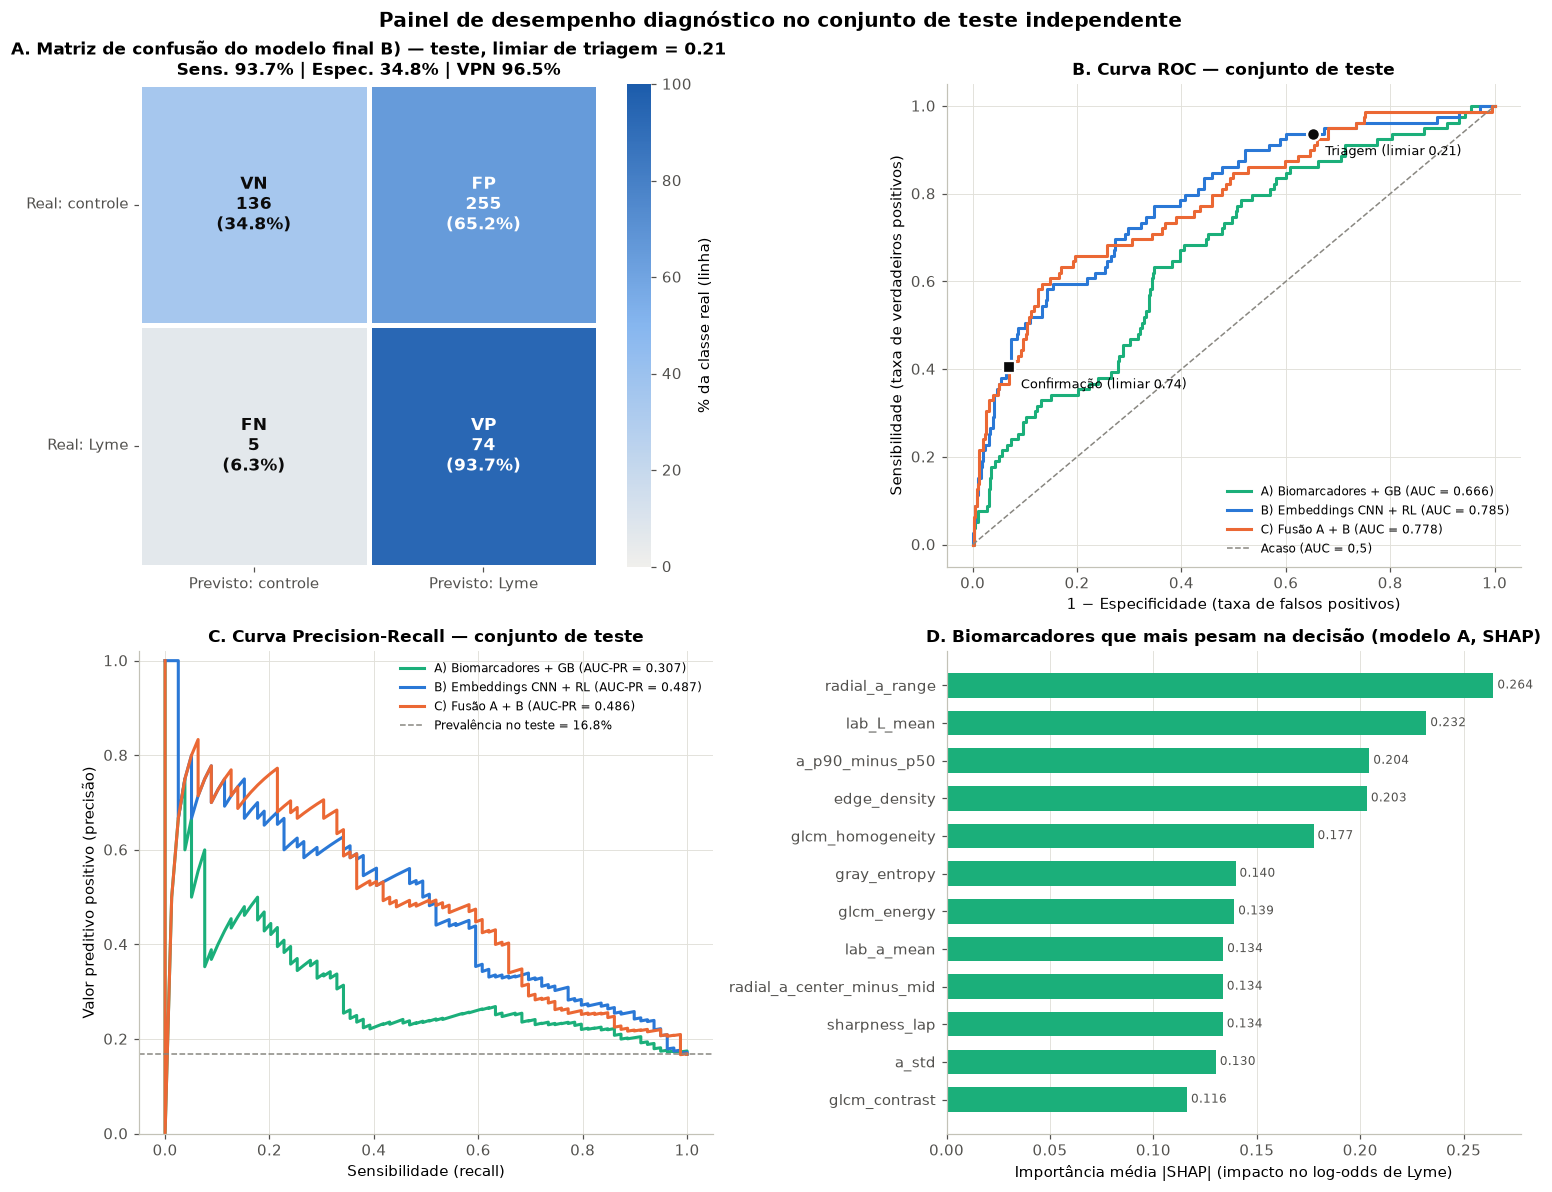

In [25]:
# ---------------------------------------------------------------
# GRAFICO 5 - Matriz de confusao + ROC + PR + importancia (SHAP)
# ---------------------------------------------------------------
fig, eixos = plt.subplots(2, 2, figsize=(14, 11))
ax_cm, ax_roc, ax_pr, ax_imp = eixos.ravel()

# (a) Matriz de confusao no limiar de triagem
m_tri = metricas(y_te, P_TE_FINAL, LIMIAR_TRIAGEM)
cm = np.array([[m_tri['VN'], m_tri['FP']], [m_tri['FN'], m_tri['VP']]])
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
sns.heatmap(cm_pct, annot=False, cmap=LinearSegmentedColormap.from_list('azul', ['#f0efec', '#86b6ef', '#1c5cab']), vmin=0, vmax=100,
            cbar_kws={'label': '% da classe real (linha)'}, linewidths=2, linecolor='white', ax=ax_cm)
rotulos_cm = [['VN', 'FP'], ['FN', 'VP']]
for i in range(2):
    for j in range(2):
        ax_cm.text(j + 0.5, i + 0.5, f'{rotulos_cm[i][j]}\n{cm[i, j]}\n({cm_pct[i, j]:.1f}%)', ha='center', va='center',
                   fontsize=11, fontweight='bold', color='white' if cm_pct[i, j] > 55 else '#0b0b0b')
ax_cm.set_xticklabels(['Previsto: controle', 'Previsto: Lyme'])
ax_cm.set_yticklabels(['Real: controle', 'Real: Lyme'], rotation=0)
ax_cm.set_title(f'A. Matriz de confusão do modelo final {NOME_FINAL[:2]} — teste, limiar de triagem = {LIMIAR_TRIAGEM:.2f}\n'
                f"Sens. {m_tri['Sensibilidade']:.1%} | Espec. {m_tri['Especificidade']:.1%} | VPN {m_tri['VPN']:.1%}")

# (b) Curvas ROC
cores_mod = {'A) Biomarcadores + GB': COR_3, 'B) Embeddings CNN + RL': COR_NEG, 'C) Fusão A + B': COR_POS}
for nome, cor in cores_mod.items():
    f, t, _ = roc_curve(y_te, p_teste[nome])
    ax_roc.plot(f, t, color=cor, lw=2, label=f'{nome} (AUC = {roc_auc_score(y_te, p_teste[nome]):.3f})')
ax_roc.plot([0, 1], [0, 1], ls='--', color=COR_NEUTRA, lw=1, label='Acaso (AUC = 0,5)')
for lim, nome_l, mk in [(LIMIAR_TRIAGEM, 'Triagem', 'o'), (LIMIAR_CONFIRMACAO, 'Confirmação', 's')]:
    mm = metricas(y_te, P_TE_FINAL, lim)
    ax_roc.scatter(1 - mm['Especificidade'], mm['Sensibilidade'], s=70, marker=mk, color='#0b0b0b', zorder=5,
                   edgecolor='white', linewidth=1.5)
    ax_roc.annotate(f'{nome_l} (limiar {lim:.2f})', (1 - mm['Especificidade'], mm['Sensibilidade']), xytext=(8, -14),
                    textcoords='offset points', fontsize=8.5)
ax_roc.set_xlabel('1 − Especificidade (taxa de falsos positivos)')
ax_roc.set_ylabel('Sensibilidade (taxa de verdadeiros positivos)')
ax_roc.set_title('B. Curva ROC — conjunto de teste')
ax_roc.legend(loc='lower right', fontsize=8)

# (c) Curvas Precision-Recall
for nome, cor in cores_mod.items():
    pr, rc, _ = precision_recall_curve(y_te, p_teste[nome])
    ax_pr.plot(rc, pr, color=cor, lw=2, label=f'{nome} (AUC-PR = {average_precision_score(y_te, p_teste[nome]):.3f})')
ax_pr.axhline(y_te.mean(), ls='--', color=COR_NEUTRA, lw=1, label=f'Prevalência no teste = {y_te.mean():.1%}')
ax_pr.set_xlabel('Sensibilidade (recall)')
ax_pr.set_ylabel('Valor preditivo positivo (precisão)')
ax_pr.set_ylim(0, 1.02)
ax_pr.set_title('C. Curva Precision-Recall — conjunto de teste')
ax_pr.legend(loc='upper right', fontsize=8)

# (d) Importancia SHAP
top_imp = importancia.tail(12)
ax_imp.barh(top_imp.index, top_imp.values, color=COR_3, height=0.65)
for i, v in enumerate(top_imp.values):
    ax_imp.text(v, i, f' {v:.3f}', va='center', fontsize=8, color=COR_TEXTO)
ax_imp.set_xlabel('Importância média |SHAP| (impacto no log-odds de Lyme)')
ax_imp.set_title('D. Biomarcadores que mais pesam na decisão (modelo A, SHAP)')
ax_imp.grid(axis='y', visible=False)
fig.suptitle('Painel de desempenho diagnóstico no conjunto de teste independente', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Leitura técnica e clínica do Gráfico 5.**
- **(A) Matriz de confusão no limiar de triagem (0,21):** o modelo detecta **74 dos 79 casos de Lyme (sensibilidade
  93,7%)**, deixando apenas 5 falsos negativos, ao custo de 255 falsos positivos (especificidade 34,8%). O **VPN de 96,5%**
  significa que um resultado "baixo risco" descarta EM com segurança razoável nesta população — é o uso adequado para a
  triagem.
- **(B) ROC:** as curvas B (azul) e C (laranja) praticamente se sobrepõem e dominam A (verde). Os marcadores indicam os
  dois pontos de operação do CDSS: triagem (alta sensibilidade) e confirmação (alta especificidade).
- **(C) Precision-Recall:** com prevalência de 16,8% (linha tracejada), o VPP do modelo B só se mantém acima de 50% enquanto a
  sensibilidade é de no máximo ~50%. Ou seja, **um alerta positivo isolado não confirma Lyme**: no máximo dobra/triplica a probabilidade
  pré-teste.
- **(D) SHAP do modelo interpretável:** os biomarcadores que mais movem a decisão são a **amplitude radial de vermelhidão**
  (valores altos ↑ suspeita), a **luminosidade L\***, o **contraste eritematoso P90 − mediana** (↑), a **densidade de bordas**
  (valores altos ↓ suspeita — lesões múltiplas, descamativas ou vesiculares sugerem diferenciais) e a **homogeneidade da
  textura** (↑). A tabela abaixo confirma a direção de cada efeito.

In [26]:
# ---------------------------------------------------------------
# Direcao do efeito SHAP: valores altos do biomarcador aumentam ou reduzem a suspeita de Lyme?
# ---------------------------------------------------------------
rho_shap = pd.Series([stats.spearmanr(X_te_A[:, i], valores_shap[:, i]).statistic
                      if np.std(X_te_A[:, i]) > 0 and np.std(valores_shap[:, i]) > 0 else np.nan
                      for i in range(len(nomes_A))], index=nomes_A)
direcao = pd.DataFrame({'Importância |SHAP|': importancia, 'ρ(valor, SHAP)': rho_shap}).sort_values('Importância |SHAP|', ascending=False).head(8)
direcao['Leitura'] = np.where(direcao['ρ(valor, SHAP)'] > 0, 'valor ALTO → ↑ suspeita de Lyme', 'valor ALTO → ↓ suspeita de Lyme')
display(direcao.round(3))

,Importância |SHAP|,"ρ(valor, SHAP)",Leitura
radial_a_range,0.264,0.832,valor ALTO → ↑ suspeita de Lyme
lab_L_mean,0.232,0.212,valor ALTO → ↑ suspeita de Lyme
a_p90_minus_p50,0.204,0.710,valor ALTO → ↑ suspeita de Lyme
edge_density,0.203,-0.692,valor ALTO → ↓ suspeita de Lyme
glcm_homogeneity,0.177,0.847,valor ALTO → ↑ suspeita de Lyme
gray_entropy,0.140,0.796,valor ALTO → ↑ suspeita de Lyme
glcm_energy,0.139,0.468,valor ALTO → ↑ suspeita de Lyme
lab_a_mean,0.134,-0.371,valor ALTO → ↓ suspeita de Lyme


#### 3.B.2 Descoberta de fenótipos (agrupamento) — Pergunta 01
Restringimos o agrupamento às **lesões de Lyme** (positivas) para responder à pergunta da Entrega 01: existem subtipos
visuais de EM? Os *embeddings* (768 dimensões) são padronizados e reduzidos por **PCA** (50 componentes); o **K-Means** é
avaliado para k = 2 … 8 com **inércia** (cotovelo), **coeficiente de silhueta** (maior = clusters mais coesos e separados;
varia de −1 a 1) e **índice de Davies-Bouldin** (menor = melhor). O perfil estatístico de cada cluster é descrito pelos
biomarcadores interpretáveis.

In [27]:
# ---------------------------------------------------------------
# 3.B.2 Agrupamento das lesoes de Lyme: PCA + K-Means
# ---------------------------------------------------------------
pos_mask = df_limpo['y'].values == 1
df_pos = df_limpo[pos_mask].reset_index(drop=True)
Z = StandardScaler().fit_transform(EMB_LIMPO[pos_mask])
pca = PCA(n_components=50, random_state=RANDOM_STATE).fit(Z)
Z_pca = pca.transform(Z)
var_acum = np.cumsum(pca.explained_variance_ratio_)
print(f'Lesões de Lyme analisadas: {len(df_pos)}')
print(f'Variância explicada: PC1 = {pca.explained_variance_ratio_[0]:.1%} | PC1+PC2 = {var_acum[1]:.1%} | '
      f'10 PCs = {var_acum[9]:.1%} | 50 PCs = {var_acum[49]:.1%}')

resultados_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z_pca)
    resultados_k.append({'k': k, 'Inércia': km.inertia_, 'Silhueta': silhouette_score(Z_pca, km.labels_),
                         'Davies-Bouldin': davies_bouldin_score(Z_pca, km.labels_)})
tab_k = pd.DataFrame(resultados_k).set_index('k')
display(tab_k.style.format({'Inércia': '{:,.0f}', 'Silhueta': '{:.3f}', 'Davies-Bouldin': '{:.3f}'})
        .highlight_max(subset=['Silhueta'], color='#cde2fb').highlight_min(subset=['Davies-Bouldin'], color='#cde2fb'))
K_OTIMO = int(tab_k['Silhueta'].idxmax())
km_final = KMeans(n_clusters=K_OTIMO, n_init=20, random_state=RANDOM_STATE).fit(Z_pca)
df_pos['cluster'] = km_final.labels_
print(f'k escolhido pela maior silhueta: {K_OTIMO}')

Lesões de Lyme analisadas: 705
Variância explicada: PC1 = 8.7% | PC1+PC2 = 13.5% | 10 PCs = 35.6% | 50 PCs = 66.3%


,Inércia,Silhueta,Davies-Bouldin
k,,,
2,"324,631",0.099,2.998
3,"311,118",0.064,3.370
4,"301,327",0.060,3.375
5,"292,455",0.059,3.243
6,"284,913",0.057,3.112
7,"279,610",0.059,3.056
8,"273,622",0.054,2.967


k escolhido pela maior silhueta: 2


#### Gráfico 4 — Padrões latentes: projeção 2D das lesões de Lyme (PCA e t-SNE) colorida pelos fenótipos encontrados

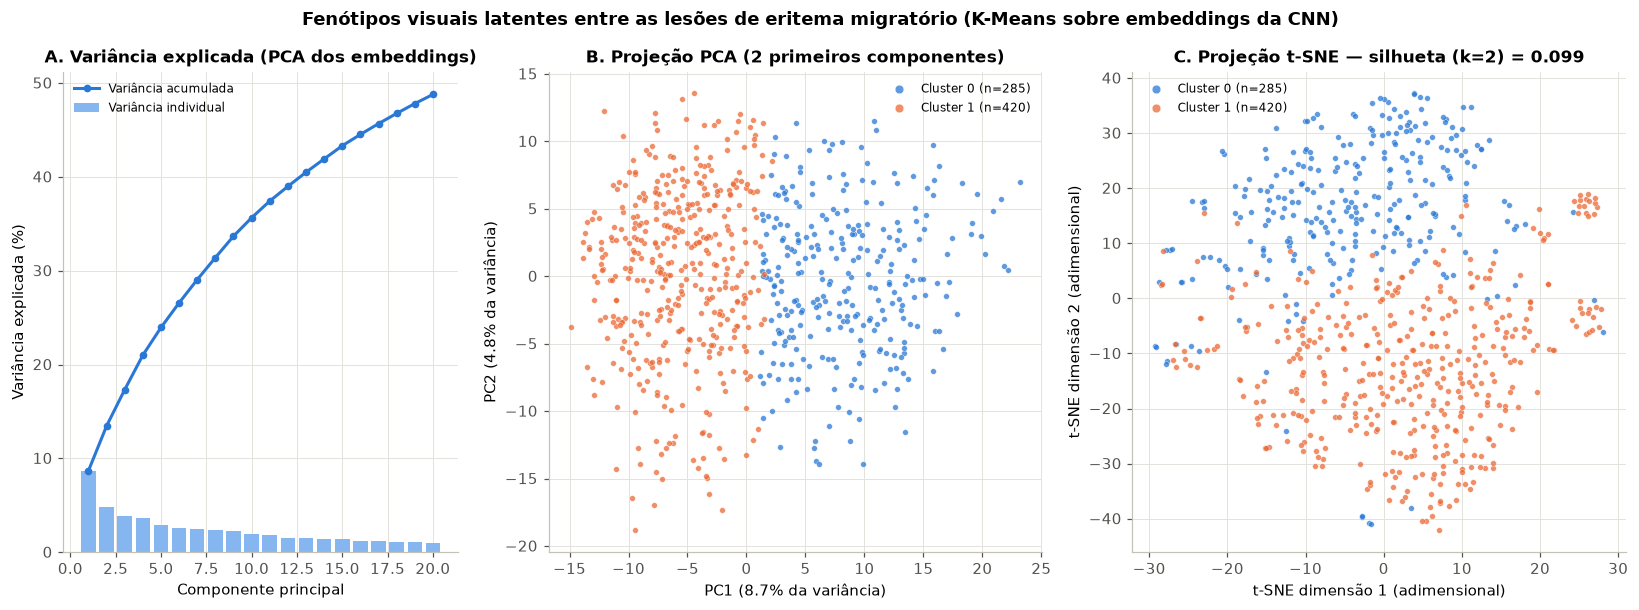

In [28]:
# ---------------------------------------------------------------
# GRAFICO 4 - Variancia explicada + projecoes 2D (PCA e t-SNE) por cluster
# ---------------------------------------------------------------
tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=RANDOM_STATE).fit_transform(Z_pca)
CORES_CLUSTER = [COR_NEG, COR_POS, COR_3, COR_4, '#eda100', '#e87ba4', '#008300', '#e34948'][:K_OTIMO]
fig = plt.figure(figsize=(15, 5.6))
gs = fig.add_gridspec(1, 3, width_ratios=[0.8, 1, 1])
ax0, ax1, ax2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])

ax0.bar(range(1, 21), pca.explained_variance_ratio_[:20] * 100, color='#86b6ef', label='Variância individual')
ax0.plot(range(1, 21), var_acum[:20] * 100, color=COR_NEG, marker='o', ms=4, lw=2, label='Variância acumulada')
ax0.set_xlabel('Componente principal')
ax0.set_ylabel('Variância explicada (%)')
ax0.set_title('A. Variância explicada (PCA dos embeddings)')
ax0.legend(fontsize=8)

for c in range(K_OTIMO):
    sel = df_pos['cluster'] == c
    rot = f'Cluster {c} (n={sel.sum()})'
    ax1.scatter(Z_pca[sel, 0], Z_pca[sel, 1], s=14, color=CORES_CLUSTER[c], alpha=0.75, edgecolor='white', linewidth=0.3, label=rot)
    ax2.scatter(tsne[sel, 0], tsne[sel, 1], s=14, color=CORES_CLUSTER[c], alpha=0.75, edgecolor='white', linewidth=0.3, label=rot)
ax1.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} da variância)')
ax1.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} da variância)')
ax1.set_title('B. Projeção PCA (2 primeiros componentes)')
ax2.set_xlabel('t-SNE dimensão 1 (adimensional)')
ax2.set_ylabel('t-SNE dimensão 2 (adimensional)')
ax2.set_title(f'C. Projeção t-SNE — silhueta (k={K_OTIMO}) = {tab_k.loc[K_OTIMO, "Silhueta"]:.3f}')
for ax in (ax1, ax2):
    ax.legend(fontsize=8, markerscale=1.5)
fig.suptitle('Fenótipos visuais latentes entre as lesões de eritema migratório (K-Means sobre embeddings da CNN)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Leitura técnica e clínica do Gráfico 4.**
(A) A variância dos *embeddings* é muito distribuída: PC1 explica 8,7%, os 10 primeiros componentes 35,6% e os 50 usados
no agrupamento 66,3% — não há um eixo dominante de variação entre as lesões. (B, C) O K-Means com **k = 2** teve a maior
silhueta (0,099) e o Davies-Bouldin fica em torno de 3,0 para todos os k: valores baixos que indicam **clusters
sobrepostos**, sem fronteira natural. A separação em B ocorre quase só ao longo de PC1 e, no t-SNE, os dois grupos são
regiões contíguas de uma mesma nuvem. **Resposta à Pergunta 01:** não há evidência de fenótipos visuais bem separados de
EM nesta base; os dois agrupamentos são tendências, e o perfil abaixo mostra o que os diferencia.

In [29]:
# ---------------------------------------------------------------
# 3.B.2 Perfil estatistico medio de cada cluster (fenotipo)
# ---------------------------------------------------------------
perfil_cols = ['lab_a_mean', 'a_p90_minus_p50', 'radial_a_center_minus_mid', 'radial_a_range', 'glcm_contrast',
               'edge_density', 'gray_entropy', 'skin_fraction', 'ita_deg_imput', 'brightness']
perfil = df_pos.groupby('cluster')[perfil_cols].median().T
perfil.columns = [f'Cluster {c} (mediana)' for c in perfil.columns]
kw = {c: stats.kruskal(*[g[c].values for _, g in df_pos.groupby('cluster')]).pvalue for c in perfil_cols}
perfil['p (Kruskal-Wallis)'] = pd.Series(kw)
display(perfil.style.format({**{c: '{:.3f}' for c in perfil.columns}, 'p (Kruskal-Wallis)': '{:.1e}'}))

print('Composição de cada cluster pelos rótulos originais de EM (% coluna):')
display((pd.crosstab(df_pos['condition'], df_pos['cluster'], normalize='columns') * 100).round(1))
print('Distribuição de tom de pele (ITA) por cluster (% coluna):')
display((pd.crosstab(df_pos['grupo_tom_pele'], df_pos['cluster'], normalize='columns') * 100).round(1))
ari = adjusted_rand_score(df_pos['condition'], df_pos['cluster'])
print(f'Índice de Rand ajustado entre clusters e rótulos de EM do dataset: {ari:.3f} (0 = concordância ao acaso)')

# Sensibilidade do classificador (OOF + teste) por cluster: algum fenotipo e mais dificil de detectar?
prob_pos = pd.concat([pd.Series(P_OOF_FINAL[y_dev == 1], index=dev.loc[y_dev == 1, 'filename']),
                      pd.Series(P_TE_FINAL[y_te == 1], index=teste.loc[y_te == 1, 'filename'])])
df_pos['prob_lyme'] = df_pos['filename'].map(prob_pos)
sens_cluster = df_pos.groupby('cluster').apply(lambda g: pd.Series({'n': len(g), 'Sensibilidade (limiar triagem)': (g.prob_lyme >= LIMIAR_TRIAGEM).mean(),
                                                                    'Prob. mediana de Lyme': g.prob_lyme.median()}), include_groups=False)
display(sens_cluster.style.format({'n': '{:.0f}', 'Sensibilidade (limiar triagem)': '{:.1%}', 'Prob. mediana de Lyme': '{:.3f}'}))

,Cluster 0 (mediana),Cluster 1 (mediana),p (Kruskal-Wallis)
lab_a_mean,13.185,8.720,1.1e-17
a_p90_minus_p50,9.570,10.110,5.8e-02
radial_a_center_minus_mid,2.865,2.869,9.1e-01
radial_a_range,10.416,9.729,8.2e-01
glcm_contrast,1.305,3.097,7.4e-35
edge_density,0.009,0.031,7.3e-59
gray_entropy,6.846,7.205,8.0e-18
skin_fraction,0.907,0.706,4.0e-31
ita_deg_imput,43.822,32.361,1.8e-08
brightness,148.020,133.310,7.5e-12


Composição de cada cluster pelos rótulos originais de EM (% coluna):


cluster,0,1
condition,,
EM rash,27.4,38.3
Erythema Migrans,36.5,35.2
bullseye rash,36.1,26.4


Distribuição de tom de pele (ITA) por cluster (% coluna):


cluster,0,1
grupo_tom_pele,,
Escura ou sombreada (ITA ≤ 10°),16.5,27.9
Intermediária (10°–41°),29.5,33.8
Clara (ITA > 41°),54.0,38.3


Índice de Rand ajustado entre clusters e rótulos de EM do dataset: 0.009 (0 = concordância ao acaso)


,n,Sensibilidade (limiar triagem),Prob. mediana de Lyme
cluster,,,
0,285,89.1%,0.668
1,420,91.4%,0.567


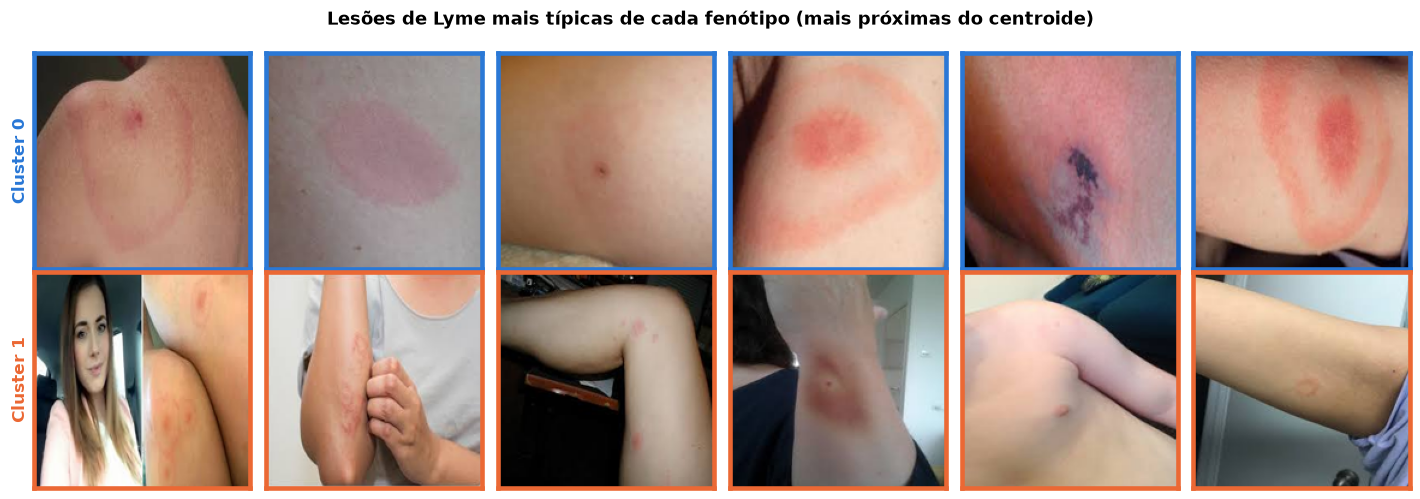

In [30]:
# ---------------------------------------------------------------
# 3.B.2 Exemplos representativos (mais proximos do centroide) de cada fenotipo
# ---------------------------------------------------------------
n_ex = 6
fig, eixos = plt.subplots(K_OTIMO, n_ex, figsize=(13, 2.3 * K_OTIMO))
eixos = np.atleast_2d(eixos)
for c in range(K_OTIMO):
    dist = np.linalg.norm(Z_pca - km_final.cluster_centers_[c], axis=1)
    dist[df_pos['cluster'].values != c] = np.inf
    for j, i in enumerate(np.argsort(dist)[:n_ex]):
        ax = eixos[c, j]
        ax.imshow(Image.open(caminho_imagem(df_pos.iloc[i])).convert('RGB').resize((180, 180)))
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(True); s.set_color(CORES_CLUSTER[c]); s.set_linewidth(3)
        if j == 0:
            ax.set_ylabel(f'Cluster {c}', fontsize=11, fontweight='bold', color=CORES_CLUSTER[c])
fig.suptitle('Lesões de Lyme mais típicas de cada fenótipo (mais próximas do centroide)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Perfil dos fenótipos e correspondência clínica.**
- **Cluster 0 (n = 285) — "lesão em close-up":** fotos enquadradas na lesão (91% de pele visível), textura lisa
  (contraste GLCM 1,3; bordas 0,009), mais vermelhas (a* 13,2), mais claras e iluminadas (ITA 43,8°; brilho 148). Os
  exemplos mostram EM únicos, grandes, vários com aspecto em alvo — próximos da apresentação de livro-texto.
- **Cluster 1 (n = 420) — "lesão em contexto":** enquadramento aberto (71% de pele), mais bordas e textura (roupas,
  móveis, membros inteiros), vermelhidão média menor (a* 8,7), mais fotos escuras/sombreadas (27,9% × 16,5%). Inclui lesões
  pequenas, múltiplas e sutis, fotografadas como num atendimento real ou por telemedicina.
- As variáveis do **padrão radial não diferem** entre os clusters (Kruskal-Wallis p = 0,91 e 0,82) e a composição pelos
  rótulos "bullseye rash", "EM rash" e "Erythema Migrans" é quase a mesma (Rand ajustado = 0,009). Logo, **os clusters
  refletem sobretudo o modo de fotografar, não estágios clínicos** (precoce × tardio, localizado × disseminado), que
  exigiriam data de início e sintomas — inexistentes na base.
- **Utilidade para o CDSS:** o modelo atribui probabilidade mediana menor às lesões do Cluster 1 (0,567 × 0,668), embora a
  sensibilidade no limiar de triagem seja semelhante (91,4% × 89,1%). Na prática, **fotos em contexto, sombreadas ou com a
  lesão pequena no quadro devem gerar um pedido de nova foto padronizada** (close-up, luz difusa, régua) antes da decisão.

#### 3.B.3 Pergunta 03 (predição temporal / regressão) — por que não foi modelada nesta base
A Pergunta 03 da Entrega 01 pedia modelar a **expansão da lesão no tempo** (cm/dia) e o risco de disseminação. A análise
de qualidade da Seção 2.1 mostrou que a fonte **não registra** nenhuma variável temporal ou métrica física: não há data da
picada, dias de evolução, diâmetro em centímetros (as fotos não têm régua/escala) nem fotos seriadas do mesmo paciente.
Ajustar uma regressão sobre um alvo inventado produziria MAE/RMSE/R² sem significado clínico — o que seria pior do que não
responder. Por isso a dupla implementou as duas outras abordagens analíticas exigidas (classificação e agrupamento) e
documenta aqui o **protocolo** para responder à Pergunta 03 numa próxima coleta:

| Elemento | Especificação |
|---|---|
| Dados necessários | Fotos seriadas (D0, D2, D4…) com régua milimetrada, data da picada/início, local anatômico, desfecho (disseminação: EM múltiplo, paralisia facial, cardite) |
| Alvo contínuo | Diâmetro do EM em cm (segmentação + calibração pela régua) e taxa de expansão (cm/dia) |
| Modelo | Regressão de efeitos mistos (intercepto/inclinação por paciente) ou curva de crescimento radial não linear |
| Métricas | **MAE e RMSE em cm** (ex.: MAE de 0,5 cm não muda conduta; erro de 2–3 cm pode cruzar o critério de 5 cm do EM) e **R²** |
| Uso clínico | Lesão que cresce > 2–3 cm/dia após picada de carrapato reforça EM (picadas e reações de hipersensibilidade regridem em 24–48 h) |

## Seção 04 — Interpretação dos dados para a tomada de decisão clínica (CDSS) — Pergunta 04
Esta seção traduz as métricas em **regras de uso clínico**. Os limiares foram escolhidos **apenas** com as probabilidades
fora-do-fold do desenvolvimento e depois verificados uma única vez no teste.

In [31]:
# ---------------------------------------------------------------
# 4.2 Pontos de operacao do CDSS avaliados no conjunto de teste
# ---------------------------------------------------------------
pontos = {'Padrão (0,50)': 0.5, f'Triagem (sens. ≥ 90%) = {LIMIAR_TRIAGEM:.2f}': LIMIAR_TRIAGEM,
          f'Youden = {LIMIAR_YOUDEN:.2f}': LIMIAR_YOUDEN, f'Confirmação (espec. ≥ 95%) = {LIMIAR_CONFIRMACAO:.2f}': LIMIAR_CONFIRMACAO}
linhas = []
for nome, lim in pontos.items():
    m = metricas(y_te, P_TE_FINAL, lim)
    inf, sup = ic_bootstrap(y_te, P_TE_FINAL, lim, n=500)
    linhas.append({'Ponto de operação': nome,
                   'Sensibilidade [IC95%]': f"{m['Sensibilidade']:.1%} [{inf['Sensibilidade']:.1%}–{sup['Sensibilidade']:.1%}]",
                   'Especificidade [IC95%]': f"{m['Especificidade']:.1%} [{inf['Especificidade']:.1%}–{sup['Especificidade']:.1%}]",
                   'VPP': f"{m['VPP (precisão)']:.1%}", 'VPN': f"{m['VPN']:.1%}", 'F1': f"{m['F1-Score']:.3f}",
                   'FN (Lyme perdidos)': m['FN'], 'FP (alarmes falsos)': m['FP']})
display(pd.DataFrame(linhas).style.hide(axis='index'))

Ponto de operação,Sensibilidade [IC95%],Especificidade [IC95%],VPP,VPN,F1,FN (Lyme perdidos),FP (alarmes falsos)
"Padrão (0,50)",62.0% [51.9%–72.2%],76.0% [71.9%–80.1%],34.3%,90.8%,0.441,30,94
Triagem (sens. ≥ 90%) = 0.21,93.7% [88.6%–98.7%],34.8% [30.0%–39.6%],22.5%,96.5%,0.363,5,255
Youden = 0.50,62.0% [51.9%–72.2%],76.2% [72.4%–80.3%],34.5%,90.9%,0.443,30,93
Confirmação (espec. ≥ 95%) = 0.74,40.5% [30.4%–51.9%],93.1% [90.4%–95.5%],54.2%,88.6%,0.464,47,27


In [32]:
# ---------------------------------------------------------------
# 4.2 Calibracao das probabilidades (Platt) e efeito da prevalencia real no VPP
# ---------------------------------------------------------------
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
platt = LogisticRegression().fit(logit(P_OOF_FINAL).reshape(-1, 1), y_dev)      # ajustado so no desenvolvimento
P_TE_CAL = platt.predict_proba(logit(P_TE_FINAL).reshape(-1, 1))[:, 1]
print(f'Brier score no teste — antes da calibração: {brier_score_loss(y_te, P_TE_FINAL):.4f} | '
      f'após calibração de Platt: {brier_score_loss(y_te, P_TE_CAL):.4f} | modelo ingênuo (prevalência): '
      f'{brier_score_loss(y_te, np.full(len(y_te), y_dev.mean())):.4f}')
LIMIAR_TRIAGEM_CAL = platt.predict_proba(logit(np.array([[LIMIAR_TRIAGEM]])))[0, 1]
LIMIAR_CONFIRMACAO_CAL = platt.predict_proba(logit(np.array([[LIMIAR_CONFIRMACAO]])))[0, 1]
print(f'Limiares expressos como probabilidade calibrada: triagem = {LIMIAR_TRIAGEM_CAL:.1%} | confirmação = {LIMIAR_CONFIRMACAO_CAL:.1%}')

# Teorema de Bayes: VPP/VPN do ponto de triagem em diferentes cenarios de prevalencia
m_tri = metricas(y_te, P_TE_FINAL, LIMIAR_TRIAGEM)
sens, espec = m_tri['Sensibilidade'], m_tri['Especificidade']
cenarios = {'Este dataset (curado)': y_te.mean(), 'Ambulatório em área endêmica (EUA/Europa), lesão anelar': 0.30,
            'Atenção primária, qualquer lesão eritematosa': 0.05, 'Brasil (Baggio-Yoshinari), lesão eritematosa': 0.005}
tab_prev = pd.DataFrame([{'Cenário': k, 'Prevalência': f'{p:.1%}',
                          'VPP (triagem)': f'{sens * p / (sens * p + (1 - espec) * (1 - p)):.1%}',
                          'VPN (triagem)': f'{espec * (1 - p) / (espec * (1 - p) + (1 - sens) * p):.2%}'} for k, p in cenarios.items()])
display(tab_prev.style.hide(axis='index'))

Brier score no teste — antes da calibração: 0.1734 | após calibração de Platt: 0.1132 | modelo ingênuo (prevalência): 0.1399
Limiares expressos como probabilidade calibrada: triagem = 6.5% | confirmação = 36.8%


Cenário,Prevalência,VPP (triagem),VPN (triagem)
Este dataset (curado),16.8%,22.5%,96.45%
"Ambulatório em área endêmica (EUA/Europa), lesão anelar",30.0%,38.1%,92.77%
"Atenção primária, qualquer lesão eritematosa",5.0%,7.0%,99.05%
"Brasil (Baggio-Yoshinari), lesão eritematosa",0.5%,0.7%,99.91%


#### Gráfico 6 — Zonas de decisão do CDSS e confiabilidade das probabilidades

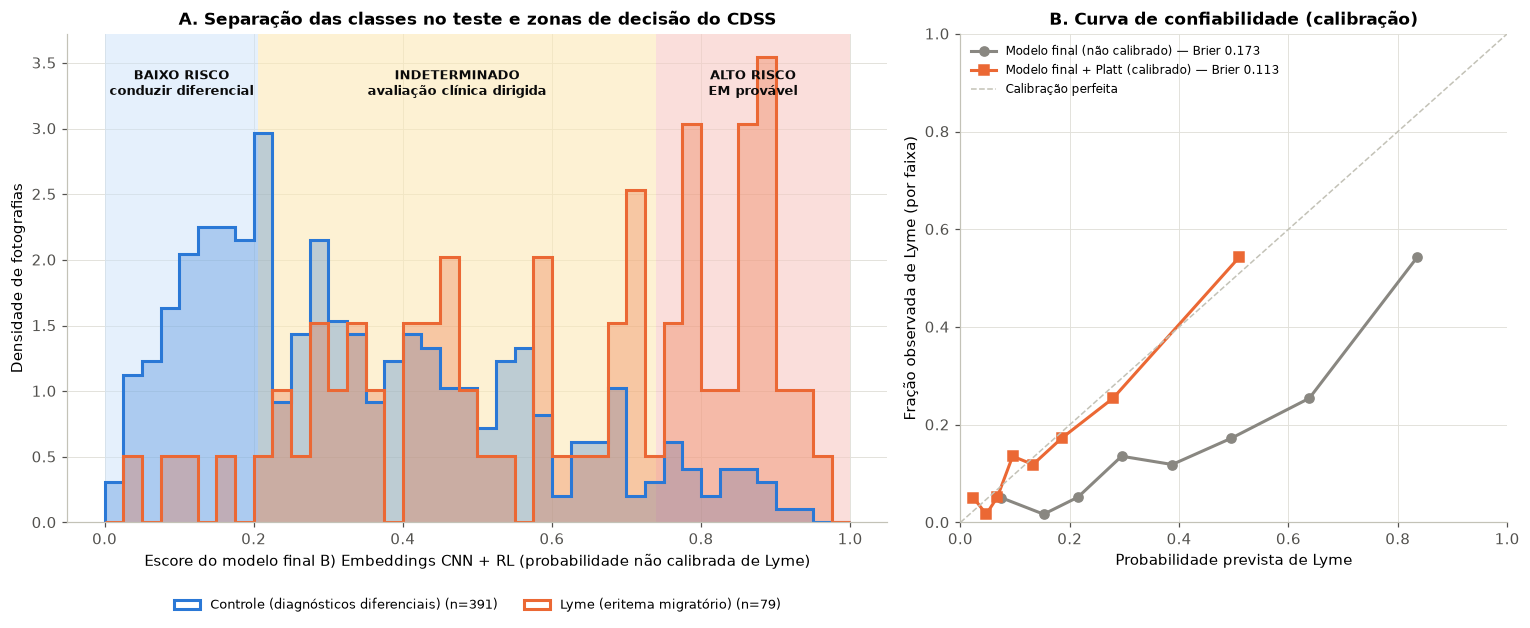

In [33]:
# ---------------------------------------------------------------
# GRAFICO 6 - Distribuicao das probabilidades por classe com zonas de risco + curva de calibracao
# ---------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={'width_ratios': [1.5, 1]})
bins = np.linspace(0, 1, 41)
ax1.axvspan(0, LIMIAR_TRIAGEM, color='#cde2fb', alpha=0.5, lw=0)
ax1.axvspan(LIMIAR_TRIAGEM, LIMIAR_CONFIRMACAO, color='#fde9b6', alpha=0.6, lw=0)
ax1.axvspan(LIMIAR_CONFIRMACAO, 1, color='#f7c9c4', alpha=0.6, lw=0)
for classe, cor in [(0, COR_NEG), (1, COR_POS)]:
    rot = f'{ROTULO[classe]} (n={(y_te == classe).sum()})'
    ax1.hist(P_TE_FINAL[y_te == classe], bins=bins, color=cor, alpha=0.30, density=True, histtype='stepfilled')
    ax1.hist(P_TE_FINAL[y_te == classe], bins=bins, color=cor, lw=2, density=True, histtype='step', label=rot)
topo = ax1.get_ylim()[1]
for x0, x1, txt in [(0, LIMIAR_TRIAGEM, 'BAIXO RISCO\nconduzir diferencial'), (LIMIAR_TRIAGEM, LIMIAR_CONFIRMACAO, 'INDETERMINADO\navaliação clínica dirigida'),
                    (LIMIAR_CONFIRMACAO, 1, 'ALTO RISCO\nEM provável')]:
    ax1.text((x0 + x1) / 2, topo * 0.93, txt, ha='center', va='top', fontsize=8.5, fontweight='bold', color='#0b0b0b')
ax1.set_xlabel(f'Escore do modelo final {NOME_FINAL} (probabilidade não calibrada de Lyme)')
ax1.set_ylabel('Densidade de fotografias')
ax1.set_title('A. Separação das classes no teste e zonas de decisão do CDSS')
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=8.5)

for p, nome, cor, mk in [(P_TE_FINAL, 'Modelo final (não calibrado)', COR_NEUTRA, 'o'), (P_TE_CAL, 'Modelo final + Platt (calibrado)', COR_POS, 's')]:
    frac, media = calibration_curve(y_te, p, n_bins=8, strategy='quantile')
    ax2.plot(media, frac, marker=mk, color=cor, lw=2, ms=6, label=f'{nome} — Brier {brier_score_loss(y_te, p):.3f}')
ax2.plot([0, 1], [0, 1], ls='--', color='#c3c2b7', lw=1, label='Calibração perfeita')
ax2.set_xlabel('Probabilidade prevista de Lyme')
ax2.set_ylabel('Fração observada de Lyme (por faixa)')
ax2.set_title('B. Curva de confiabilidade (calibração)')
ax2.legend(fontsize=8, loc='upper left')
ax2.set_xlim(0, 1); ax2.set_ylim(0, 1)
plt.tight_layout()
plt.show()

**Leitura técnica e clínica do Gráfico 6.**
(A) As densidades são normalizadas por classe: os controles (azul) concentram-se abaixo de 0,4 e os casos de Lyme
(laranja) têm o pico entre 0,75 e 0,9, mas há ampla sobreposição entre 0,2 e 0,7 — é por isso que existe a **zona
indeterminada**: o CDSS reconhece explicitamente que, nessa faixa, a foto não basta e a decisão volta para a anamnese.
Na zona de baixo risco quase só há controles (VPN 96,5%); na de alto risco, pouco mais da metade das fotos é de Lyme
(VPP 54,2%), porque há 5 controles para cada caso e mesmo uma pequena fração deles ultrapassa o limiar. (B) O modelo bruto (cinza) fica abaixo da diagonal: quando ele diz
"80%", a frequência observada de Lyme é ~55%. A versão calibrada (laranja) acompanha a diagonal — condição necessária para
que a probabilidade seja comunicada ao médico e ao paciente sem induzir excesso de confiança.

### 4.3 Explicabilidade visual (XAI)

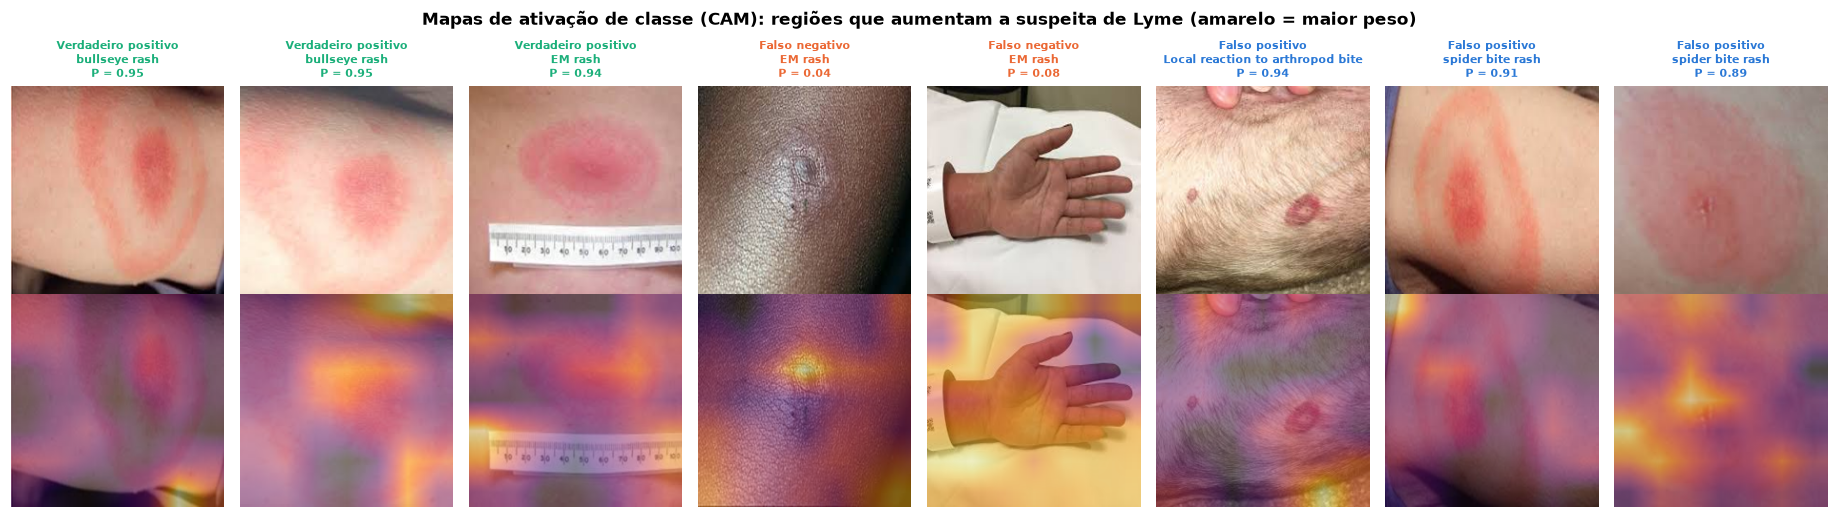

In [34]:
# ---------------------------------------------------------------
# 4.3 Explicabilidade visual (CAM) do modelo B: onde a CNN "olha"?
# ---------------------------------------------------------------
# Para uma sonda linear sobre a media global dos mapas de ativacao, o mapa de ativacao de classe (CAM, Zhou et al., 2016)
# e exato: CAM(x,y) = soma_k (w_k / sigma_k) * A_k(x,y), onde w sao os pesos da regressao e sigma o desvio do StandardScaler.
rede_cam, transf_cam = carregar_backbone()
pesos_cam = torch.tensor(mod_B[-1].coef_[0] / mod_B[0].scale_, dtype=torch.float32)

def mapa_cam(linha):
    img = Image.open(caminho_imagem(linha)).convert('RGB')
    with torch.no_grad():
        A = rede_cam.features(transf_cam(img).unsqueeze(0).to(DEVICE))[0].cpu()
    cam = torch.einsum('k,khw->hw', pesos_cam, A).numpy()
    cam = np.asarray(Image.fromarray(cam.astype(np.float32)).resize((224, 224), Image.BILINEAR))
    return img.resize((224, 224)), (cam - cam.min()) / (cam.max() - cam.min() + 1e-9)

teste_aval = teste.assign(prob=P_TE_FINAL)
casos = pd.concat([
    teste_aval[teste_aval.y == 1].nlargest(3, 'prob').assign(tipo='Verdadeiro positivo'),
    teste_aval[(teste_aval.y == 1)].nsmallest(2, 'prob').assign(tipo='Falso negativo'),
    teste_aval[teste_aval.y == 0].nlargest(3, 'prob').assign(tipo='Falso positivo'),
])
fig, eixos = plt.subplots(2, len(casos), figsize=(2.1 * len(casos), 4.8))
for j, (_, linha) in enumerate(casos.iterrows()):
    img, cam = mapa_cam(linha)
    eixos[0, j].imshow(img)
    eixos[1, j].imshow(img)
    eixos[1, j].imshow(cam, cmap='inferno', alpha=0.5)
    cor = {'Verdadeiro positivo': COR_3, 'Falso negativo': COR_POS, 'Falso positivo': COR_NEG}[linha['tipo']]
    eixos[0, j].set_title(f"{linha['tipo']}\n{linha['condition']}\nP = {linha['prob']:.2f}", fontsize=7.5, color=cor)
    for ax in eixos[:, j]:
        ax.axis('off')
fig.suptitle('Mapas de ativação de classe (CAM): regiões que aumentam a suspeita de Lyme (amarelo = maior peso)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

**Leitura dos mapas de ativação (CAM).**
- Nos **verdadeiros positivos**, parte da ativação recai sobre a lesão e seus anéis, mas também sobre **bordas da imagem
  e sobre a régua milimetrada** (3ª foto). Réguas são comuns em fotos de EM porque o critério diagnóstico exige ≥ 5 cm — o
  modelo pode estar aprendendo um **atalho (*shortcut learning*)**: "foto com régua = Lyme".
- **Falsos negativos:** o 1º é um **EM em pele negra** (P = 0,04) — o eritema fica violáceo/acastanhado e de baixo contraste,
  padrão raro no treino; o 2º é uma mão sem lesão visível rotulada como "EM rash", provável ruído de rótulo remanescente.
- **Falsos positivos:** reação a picada de artrópode e "picadas de aranha" com halo eritematoso concêntrico — mimetizadores
  legítimos do EM que também confundem clínicos. Aqui a anamnese (picada percebida, dor, evolução em 24–48 h) é o que
  desempata.
- **Conclusão:** o CAM confirma que o modelo **não deve ser usado sem revisão humana** da imagem e mostra onde ele falha —
  informação que deve ser apresentada junto com o escore no CDSS.

### 4.1 Hierarquia de biomarcadores e triagem
Combinando os tamanhos de efeito (Seção 3.A), o SHAP (Gráfico 5D) e a literatura clínica, os indicadores mais
determinantes para suspeitar precocemente de EM são, em ordem:

1. **Padrão radial / anelar da vermelhidão** (`radial_a_range`, `radial_a_center_minus_mid`) — lesão centrada com anéis
   concêntricos; maior efeito univariado e maior importância SHAP.
2. **Contraste eritematoso relativo** (`a_p90_minus_p50`) — o quanto a lesão se destaca da pele vizinha, mais informativo
   que a vermelhidão absoluta (que não difere entre os grupos).
3. **Textura homogênea e poucas bordas** (`glcm_homogeneity` ↑, `edge_density` ↓) — mácula lisa favorece EM; descamação
   (tinea), vesículas em faixa (herpes-zóster) ou lesões múltiplas pequenas favorecem diferenciais.
4. **Padrão espacial aprendido pela CNN** (*embeddings*) — o preditor mais forte em conjunto (AUC 0,785), que integra
   forma, borda e tamanho relativo.
5. **Qualidade/contexto da foto** (fração de pele, brilho, ITA) — não é biomarcador da doença, mas **modula a confiança**
   do resultado e deve disparar o pedido de nova foto.

**Otimização de exames:** como as diretrizes não recomendam sorologia para EM típico, o ganho do CDSS não é "pedir menos
ELISA", e sim **evitar sorologias inúteis na fase aguda** (negativas na janela imunológica e geradoras de falsa
tranquilidade), **evitar biópsia/PCR de pele** em lesões de alta probabilidade e **direcionar exames apenas a quem
realmente precisa**: casos indeterminados com sintomas sistêmicos (sorologia pareada após 2–4 semanas) e casos
disseminados (ECG para bloqueio AV; avaliação neurológica/punção lombar apenas se houver sinais neurológicos).

### 4.2 Definição de limiares de risco (*threshold tuning*)
O corte padrão de 0,50 é inadequado: ele deixa 30 dos 79 casos de Lyme sem diagnóstico (sensibilidade 62%). A dupla
recomenda **dois limiares**, escolhidos com as probabilidades fora-do-fold e verificados no teste:

| Zona | Escore do modelo B | Prob. calibrada | Desempenho no teste | Uso |
|---|---|---|---|---|
| **Baixo risco** | < 0,21 | < 6,5% | Sens. 93,7%, **VPN 96,5%** (5 FN em 79) | Triagem primária: EM improvável → investigar o diagnóstico diferencial |
| **Indeterminado** | 0,21 – 0,74 | 6,5% – 36,8% | Mistura de casos | Avaliação clínica dirigida (anamnese de picada, evolução, sintomas) |
| **Alto risco** | ≥ 0,74 | ≥ 36,8% | **Espec. 93,1%**, VPP 54,2% | Confirmação: EM provável → tratar se a anamnese for compatível |

Dois cuidados quantitativos sustentam essa recomendação:
- **Calibração:** o escore bruto superestima o risco (efeito da ponderação de classes; Brier 0,173, pior que o modelo
  ingênuo 0,140). Após a **calibração de Platt** ajustada só no desenvolvimento, o Brier cai para **0,113** — a
  probabilidade exibida ao médico deve ser a calibrada.
- **Prevalência:** VPP e VPN dependem da população. Com os mesmos limiares, o VPP de um alerta de triagem é 38% numa clínica
  de área endêmica (prevalência 30%), 7% na atenção primária (5%) e **0,7% num cenário brasileiro** (0,5%), onde o VPN chega
  a 99,9%. **No Brasil, o modelo só faz sentido como ferramenta de descarte, nunca como confirmação.**

## Seção 05 — Análise crítica e ética contextualizada na Doença de Lyme
A discussão abaixo é ancorada nos números deste notebook (duplicatas, tom de pele, erros do modelo) e nas particularidades
clínicas e epidemiológicas da borreliose — não em considerações genéricas sobre IA.

### 5.1 Vieses de dados e representatividade epidemiológica — auditoria quantitativa
O dataset não traz sexo, idade nem etnia (Seção 2.1). A única dimensão demográfica que conseguimos **estimar** é o tom de
pele, pelo Ângulo Tipológico Individual (ITA° = arctan[(L* − 50)/b*]) medido na pele perilesional. É um *proxy* grosseiro
(depende de iluminação, balanço de branco e compressão das fotos da web), mas suficiente para auditar se o desempenho
muda entre grupos.

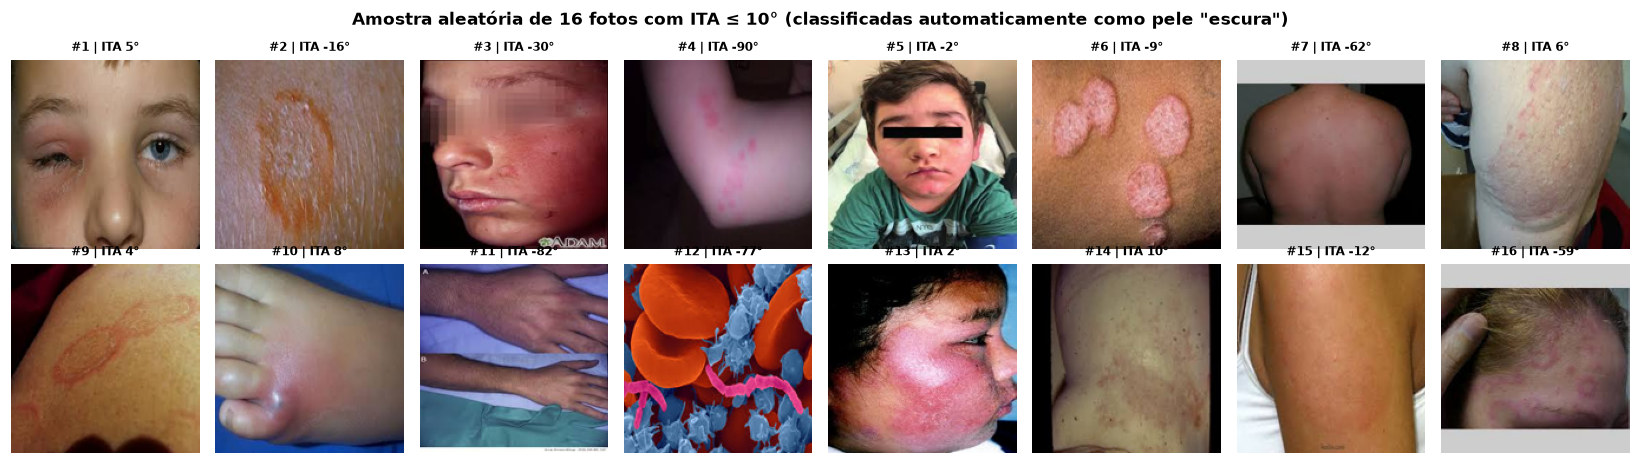

In [35]:
# ---------------------------------------------------------------
# 5.1 Validacao visual do proxy ITA: o grupo "ITA <= 10" e realmente pele escura?
# ---------------------------------------------------------------
amostra_ita = df_limpo[df_limpo['ita_deg'] <= 10].sample(16, random_state=RANDOM_STATE)
fig, eixos = plt.subplots(2, 8, figsize=(15, 4.3))
for k, (ax, (_, linha)) in enumerate(zip(eixos.ravel(), amostra_ita.iterrows())):
    ax.imshow(Image.open(caminho_imagem(linha)).convert('RGB').resize((160, 160)))
    ax.set_title(f"#{k + 1} | ITA {linha['ita_deg']:.0f}°", fontsize=8)
    ax.axis('off')
fig.suptitle('Amostra aleatória de 16 fotos com ITA ≤ 10° (classificadas automaticamente como pele "escura")', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

**Validação do proxy de tom de pele.** Na amostra aleatória acima, das 16 fotos classificadas automaticamente como pele
"escura" (ITA ≤ 10°), **no máximo 3 (#2, #7 e #13) mostram de fato pele mais pigmentada**; as demais são peles claras em
sombra, com luz quente/avermelhada, *flash* ou fundo escuro, e a #12 sequer é uma foto de pele (é uma ilustração de
espiroquetas e hemácias rotulada como "celulite bacteriana" — mais um ruído de coleta). Junto com a correlação ITA × brilho
de 0,68 (Gráfico 3), isso mostra que, em fotos não padronizadas da internet, **o ITA mede "tom aparente" (fototipo +
iluminação), e não fototipo**. A auditoria abaixo deve ser lida assim: o grupo "escura ou sombreada" contém poucas peles
realmente pigmentadas e muitas fotos mal iluminadas — e **a própria escassez de pele pigmentada já é um achado de viés**.

In [36]:
# ---------------------------------------------------------------
# 5.1 Equidade: desempenho do CDSS por tom de pele (ITA)
# ---------------------------------------------------------------
def ic_wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    centro = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    meia = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centro - meia, centro + meia

aval = pd.concat([dev.assign(prob=P_OOF_FINAL, origem='Desenvolvimento (fora-do-fold)'),
                  teste.assign(prob=P_TE_FINAL, origem='Teste')], ignore_index=True)
aval['grupo_tom_pele'] = aval['grupo_tom_pele'].cat.add_categories('ITA ausente').fillna('ITA ausente')
linhas = []
for g, sub in aval.groupby('grupo_tom_pele', observed=True):
    pos, neg = sub[sub.y == 1], sub[sub.y == 0]
    vp, vn = (pos.prob >= LIMIAR_TRIAGEM).sum(), (neg.prob < LIMIAR_TRIAGEM).sum()
    li, ls = ic_wilson(vp, len(pos))
    linhas.append({'Tom de pele (ITA)': g, 'Fotos': len(sub), '% da base': len(sub) / len(aval) * 100, 'Lyme (n)': len(pos),
                   'Sensibilidade': vp / len(pos) if len(pos) else np.nan, 'IC95% inf.': li, 'IC95% sup.': ls,
                   'Especificidade': vn / len(neg), 'AUC-ROC': roc_auc_score(sub.y, sub.prob) if sub.y.nunique() == 2 else np.nan})
tab_eq = pd.DataFrame(linhas)
display(tab_eq.style.format({'% da base': '{:.1f}%', 'Sensibilidade': '{:.1%}', 'IC95% inf.': '{:.1%}', 'IC95% sup.': '{:.1%}',
                             'Especificidade': '{:.1%}', 'AUC-ROC': '{:.3f}'}).hide(axis='index'))

Tom de pele (ITA),Fotos,% da base,Lyme (n),Sensibilidade,IC95% inf.,IC95% sup.,Especificidade,AUC-ROC
Escura ou sombreada (ITA ≤ 10°),1251,28.1%,164,82.9%,76.4%,87.9%,34.7%,0.705
Intermediária (10°–41°),1303,29.3%,226,93.4%,89.3%,95.9%,29.3%,0.790
Clara (ITA > 41°),1882,42.3%,315,92.4%,88.9%,94.8%,31.1%,0.772
ITA ausente,15,0.3%,0,nan%,nan%,nan%,33.3%,nan


#### Gráfico 7 — Auditoria de equidade: representatividade e sensibilidade por tom de pele

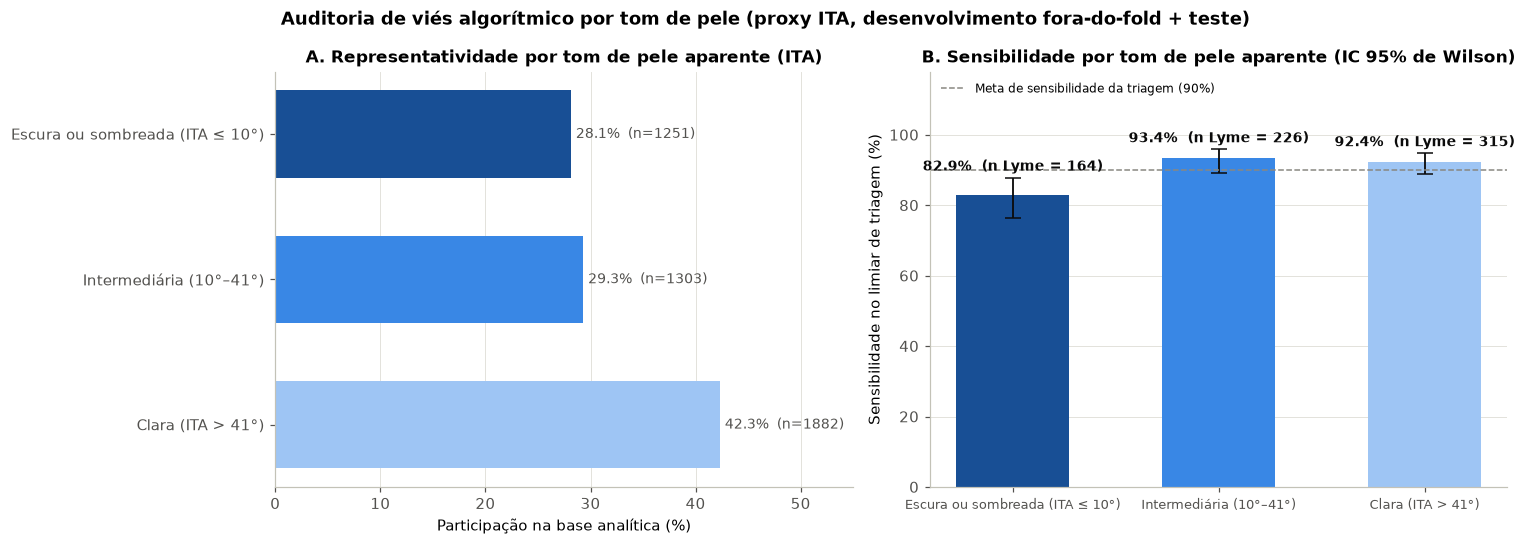

In [37]:
# ---------------------------------------------------------------
# GRAFICO 7 - Representatividade e sensibilidade por tom de pele
# ---------------------------------------------------------------
eq = tab_eq[tab_eq['Tom de pele (ITA)'] != 'ITA ausente'].reset_index(drop=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
cores_eq = ['#184f95', '#3987e5', '#9ec5f4']
ax1.barh(eq['Tom de pele (ITA)'], eq['% da base'], color=cores_eq, height=0.6)
ax1.invert_yaxis()
for i, (v, n) in enumerate(zip(eq['% da base'], eq['Fotos'])):
    ax1.text(v + 0.5, i, f'{v:.1f}%  (n={n})', va='center', fontsize=9, color=COR_TEXTO)
ax1.set_xlabel('Participação na base analítica (%)')
ax1.set_title('A. Representatividade por tom de pele aparente (ITA)')
ax1.set_xlim(0, eq['% da base'].max() * 1.3)
ax1.grid(axis='y', visible=False)

x = np.arange(len(eq))
ax2.bar(x, eq['Sensibilidade'] * 100, color=cores_eq, width=0.55)
ax2.errorbar(x, eq['Sensibilidade'] * 100, yerr=[(eq['Sensibilidade'] - eq['IC95% inf.']) * 100, (eq['IC95% sup.'] - eq['Sensibilidade']) * 100],
             fmt='none', ecolor='#0b0b0b', capsize=5, lw=1.2)
for i, (s, sup, n) in enumerate(zip(eq['Sensibilidade'], eq['IC95% sup.'], eq['Lyme (n)'])):
    ax2.text(i, sup * 100 + 2, f'{s:.1%}  (n Lyme = {n})', ha='center', fontsize=9, color='#0b0b0b', fontweight='bold')
ax2.axhline(90, ls='--', color=COR_NEUTRA, lw=1, label='Meta de sensibilidade da triagem (90%)')
ax2.set_xticks(x)
ax2.set_xticklabels(eq['Tom de pele (ITA)'], fontsize=8.5)
ax2.set_ylabel('Sensibilidade no limiar de triagem (%)')
ax2.set_ylim(0, 118)
ax2.set_title('B. Sensibilidade por tom de pele aparente (IC 95% de Wilson)')
ax2.legend(fontsize=8, loc='upper left')
ax2.grid(axis='x', visible=False)
fig.suptitle('Auditoria de viés algorítmico por tom de pele (proxy ITA, desenvolvimento fora-do-fold + teste)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Leitura técnica e clínica do Gráfico 7.** (A) O grupo de pele clara é o mais representado (42,3%). Como mostrado acima, o
grupo "escura ou sombreada" (28,1%) é composto majoritariamente por iluminação desfavorável, e não por fototipos IV–VI.
(B) A sensibilidade no limiar de triagem é de **92–93% nos grupos claro e intermediário**, mas cai para **82,9% (IC95%
76,4–87,9%) no grupo escuro/sombreado**, abaixo da meta de 90%, com intervalos que não se sobrepõem aos do grupo
intermediário; a AUC também cai (0,705 × 0,790). Na prática: **a cada 100 pacientes com EM fotografados nessas condições,
cerca de 17 seriam liberados como "baixo risco", contra 7 a 8 nos demais grupos.** Como o falso negativo da Seção 4.3 em pele
negra ilustra, é exatamente o perfil de paciente que a literatura descreve como diagnosticado mais tarde e com doença mais
disseminada — o algoritmo, treinado com este dataset, **ampliaria a desigualdade existente**.

### 5.1 (cont.) Representatividade epidemiológica e aplicação no Brasil
- **Origem dos dados:** as fotos foram coletadas da internet (atlas dermatológicos, bancos de imagem com marca d'água,
  fóruns e sites como *BadSpiderBites.com*), sem protocolo, consentimento rastreável, país de origem ou dados demográficos.
  Não representam nenhuma população clínica definida: são **o que estava disponível on-line**, um viés de seleção que
  favorece casos clássicos e pele clara — os livros-texto de dermatologia mostram pele escura em minoria das imagens
  (Adelekun *et al.*, 2021), e modelos dermatológicos treinados assim perdem desempenho em fototipos altos (Daneshjou *et al.*, 2022).
- **Demografia da Lyme:** a doença tem distribuição bimodal por idade (crianças de 5–9 anos e adultos de 55–69 anos nos EUA)
  e predomina em populações brancas de áreas endêmicas do nordeste dos EUA e da Europa. Pacientes negros são minoria nas
  notificações, mas apresentam com mais frequência doença **já disseminada** (artrite, neuroborreliose) no diagnóstico,
  em parte porque o EM é menos reconhecido em pele pigmentada (Fix; Peña; Strickland, 2000). Sem idade e sexo na base,
  não é possível verificar se o modelo funciona em crianças (lesões em face/couro cabeludo, mais frequentes) ou em idosos.
- **Distorções no SUS / saúde suplementar:** (i) **Epidemiologia diferente:** no Brasil, o quadro é a Síndrome de
  Baggio-Yoshinari (Lyme-símile), transmitida por carrapatos *Amblyomma* e *Rhipicephalus*, com espiroquetas atípicas, EM
  presente em parte dos casos e sorologias de referência norte-americanas pouco sensíveis. Um modelo treinado com fotos de
  EM norte-americano/europeu não foi validado para essa apresentação. (ii) **Prevalência muito menor:** como calculado na
  Seção 4.2, o VPP de um alerta cai para < 1% — o CDSS geraria dezenas de alarmes falsos para cada caso real, sobrecarregando
  a atenção básica e induzindo antibioticoterapia em massa. (iii) **População miscigenada:** mais da metade da população
  brasileira (55,5%) se autodeclara parda ou preta (IBGE, Censo 2022), exatamente o grupo em que a sensibilidade cai e onde o
  dataset é mais pobre. (iv) **Diferenciais locais ausentes:** hanseníase (placas anulares), leishmaniose tegumentar,
  esporotricose e picadas de insetos regionais não estão entre os 12 diferenciais do dataset.

### 5.2 Impacto ético dos erros diagnósticos na Doença de Lyme
- **Falso negativo:** o paciente com EM não recebe doxiciclina na janela em que o tratamento oral de 10 dias é curativo em
  > 90% dos casos. Semanas depois, a borrélia pode disseminar-se por via hematogênica: **EM múltiplo, paralisia facial
  periférica (às vezes bilateral), meningite linfocitária, radiculoneurite, cardite de Lyme com bloqueio atrioventricular
  (que pode exigir marca-passo temporário e já causou mortes súbitas)** e, meses depois, **artrite de Lyme** em grandes
  articulações. O tratamento tardio passa a exigir ceftriaxona endovenosa e cursos mais longos, e uma parcela dos pacientes
  evolui com sintomas persistentes pós-tratamento. Em nosso modelo, 5 de 79 casos (6,3%) seriam perdidos na triagem —
  proporção que sobe para ~17% nas fotos de pele escura/sombreada.
- **Falso positivo:** (i) **atraso do diagnóstico correto** — é o dano mais sério: o herpes-zóster rotulado como Lyme
  perde a janela de 72 h do antiviral (risco de neuralgia pós-herpética); a celulite não recebe cobertura adequada; a
  farmacodermia continua sendo provocada pelo medicamento suspeito; a tinea tratada com corticoide piora. (ii) **Exposição
  desnecessária à doxiciclina** — fotossensibilidade, esofagite, distúrbios gastrointestinais; uso evitado na gestação;
  pressão de seleção para resistência bacteriana. (iii) **Rótulo de "doença de Lyme"** — pode levar a sorologias
  repetidas, investigação de "Lyme crônica" e a tratamentos antibióticos prolongados sem benefício comprovado e com
  danos documentados, além de ansiedade e custos. Com o limiar de triagem, 255 dos 391 controles do teste (65%) seriam
  sinalizados — por isso o alerta de triagem **não pode** acionar prescrição automática.

### 5.3 Explicabilidade (XAI), caixa-preta e autonomia médica
- Médicos e pacientes não devem confiar cegamente no alerta porque **este notebook demonstrou concretamente** como o modelo
  pode errar por motivos não clínicos: rótulos contraditórios na fonte (248 fotos), cópias que inflam métricas,
  atenção a réguas e bordas da imagem (CAM), queda de sensibilidade em pele escura/fotos sombreadas e probabilidades mal
  calibradas antes do ajuste de Platt.
- **Salvaguardas para que a ferramenta seja suporte, e não substituta:** (1) exibir sempre o **mapa CAM** e os
  **biomarcadores interpretáveis** junto com a probabilidade calibrada e seu intervalo; (2) **zona indeterminada** explícita,
  que devolve a decisão à anamnese (picada de carrapato, viagem, tempo de evolução, crescimento da lesão); (3) **controle de
  qualidade da foto** antes da inferência (pele visível, iluminação), com recusa e pedido de nova foto; (4) **nenhuma
  prescrição automática** — o médico registra a decisão final e pode discordar do sistema, e as discordâncias alimentam a
  auditoria do modelo; (5) monitoramento contínuo do desempenho por subgrupo após a implantação.
- **Regulação:** um software que sugere diagnóstico é **dispositivo médico (SaMD)** e exige regularização na ANVISA
  (RDC 657/2022); em teleconsulta, a responsabilidade pela decisão é do médico (Resolução CFM 2.314/2022).

### 5.4 Privacidade, dados sensíveis e conformidade com a LGPD
- Fotografias de lesões são **dados pessoais sensíveis referentes à saúde** (LGPD, art. 5º, II) e, quando mostram rosto,
  tatuagens ou marcas, também são **dados biométricos** potencialmente identificáveis. Neste dataset há rostos de crianças
  sem tarja, tatuagens, ambientes domésticos e marcas d'água com nomes de pessoas e sites — informação suficiente para
  reidentificar o paciente por busca reversa de imagem, mesmo sem nome no arquivo.
- **Reidentificação em doença rara:** no Brasil, a Lyme-símile tem poucos casos por município; a combinação "EM + cidade +
  data + idade" pode apontar um único paciente mesmo após a pseudonimização. A remoção do nome **não** basta.
- **Cuidados indispensáveis:** (1) **base legal** — consentimento específico e destacado (art. 11, I) ou tutela da saúde por
  profissional/serviço de saúde (art. 11, II, *f*); para pesquisa, aprovação em Comitê de Ética (CEP/CONEP) e anonimização
  sempre que possível (art. 13); (2) **minimização** — recortar a imagem na lesão, remover rosto, tatuagens e metadados EXIF
  (GPS, data, modelo do celular); (3) **generalização** de idade e localização (faixas etárias, região em vez de município)
  e supressão de células com poucos casos; (4) **segurança** — criptografia, controle de acesso e registro de quem acessa;
  (5) **governança do modelo** — embeddings e modelos treinados também podem vazar dados de treino, então não devem ser
  publicados sem avaliação; (6) **transparência** — informar o paciente de que uma IA participou da triagem (art. 20 garante
  revisão de decisões automatizadas). Por fim, o próprio dataset do Kaggle, coletado da web sem consentimento dos
  retratados, **não seria aceitável como base de um produto clínico**: serve apenas para ensino e prova de conceito.

## Seção 06 — Conclusões
1. **Qualidade dos dados:** 17,9% da base estava em grupos de duplicatas e 248 fotos tinham rótulos contraditórios; após a
   limpeza restaram 4.451 fotos (705 de Lyme, razão 5,3 : 1). Não há dados faltantes relevantes nos atributos de imagem, mas
   todas as variáveis clínicas do paciente estão ausentes na fonte.
2. **Pergunta 02 (classificação):** biomarcadores visuais isolados diferem pouco entre EM e diferenciais (|δ de Cliff| ≤
   0,17); o *transfer learning* com ConvNeXt-Tiny atinge **AUC-ROC 0,785 e AUC-PR 0,487** no teste independente. Com o limiar
   de triagem, a sensibilidade é 93,7% e o VPN 96,5%, mas a especificidade é baixa (34,8%).
3. **Pergunta 01 (agrupamento):** os *embeddings* das lesões de Lyme formam dois agrupamentos fracos (silhueta 0,099), que
   correspondem ao enquadramento da foto (close-up × contexto), e não a estágios clínicos.
4. **Pergunta 03 (temporal):** não respondível com esta base, por ausência total de variáveis temporais e de escala física;
   foi proposto um protocolo de coleta seriada com métricas de erro em centímetros.
5. **Pergunta 04 (CDSS):** recomendamos um fluxo em três zonas (escore < 0,21 / 0,21–0,74 / ≥ 0,74) com probabilidades
   calibradas, CAM e controle de qualidade da foto, sempre subordinado à anamnese e à decisão médica.
6. **Ética:** o modelo perde sensibilidade em fotos de pele escura/sombreada (82,9% × 92–93%), não foi validado para a
   Lyme-símile brasileira e teria VPP < 1% na prevalência nacional. **Antes de qualquer uso clínico** seriam necessários
   dados prospectivos, com consentimento, fototipo registrado e diversidade populacional, validação externa no Brasil e
   regularização como SaMD.

**Próximos passos técnicos:** *fine-tuning* da CNN com aumentação de dados, segmentação da lesão para eliminar atalhos (réguas,
bordas), rotulagem dermatológica independente das fotos ambíguas e coleta de metadados clínicos para modelos multimodais.

## Referências
1. CENTERS FOR DISEASE CONTROL AND PREVENTION (CDC). *Lyme Disease: Clinical Signs and Symptoms; Erythema Migrans*. Atlanta: CDC, 2024.
2. LANTOS, P. M. et al. Clinical Practice Guidelines by the IDSA, AAN and ACR: 2020 Guidelines for the Prevention, Diagnosis and Treatment of Lyme Disease. *Clinical Infectious Diseases*, v. 72, n. 1, p. e1–e48, 2021.
3. STEERE, A. C. et al. Lyme borreliosis. *Nature Reviews Disease Primers*, v. 2, 16090, 2016.
4. SMITH, R. P. et al. Clinical characteristics and treatment outcome of early Lyme disease in patients with microbiologically confirmed erythema migrans. *Annals of Internal Medicine*, v. 136, n. 6, p. 421–428, 2002.
5. BURLINA, P. M. et al. Automated detection of erythema migrans and other confounding skin lesions via deep learning. *Computers in Biology and Medicine*, v. 105, p. 151–156, 2019.
6. YOSHINARI, N. H. et al. Doença de Lyme-símile brasileira ou Síndrome Infecto-Reacional Baggio-Yoshinari: zoonose exótica e emergente transmitida por carrapatos. *Revista da Associação Médica Brasileira*, v. 56, n. 3, p. 363–369, 2010.
7. FIX, A. D.; PEÑA, C. A.; STRICKLAND, G. T. Racial differences in reported Lyme disease incidence. *American Journal of Epidemiology*, v. 152, n. 8, p. 756–759, 2000.
8. DANESHJOU, R. et al. Disparities in dermatology AI performance on a diverse, curated clinical image set. *Science Advances*, v. 8, n. 32, eabq6147, 2022.
9. ADELEKUN, A.; ONYEKABA, G.; LIPOFF, J. B. Skin color in dermatology textbooks: an updated evaluation and analysis. *Journal of the American Academy of Dermatology*, v. 84, n. 1, p. 194–196, 2021.
10. CHARDON, A.; CRETOIS, I.; HOURSEAU, C. Skin colour typology and suntanning pathways. *International Journal of Cosmetic Science*, v. 13, n. 4, p. 191–208, 1991.
11. ZHOU, B. et al. Learning Deep Features for Discriminative Localization (CAM). *CVPR*, 2016.
12. LUNDBERG, S. M.; LEE, S.-I. A Unified Approach to Interpreting Model Predictions (SHAP). *NeurIPS*, 2017.
13. LIU, Z. et al. A ConvNet for the 2020s (ConvNeXt). *CVPR*, 2022.
14. BRASIL. Lei nº 13.709, de 14 de agosto de 2018 — Lei Geral de Proteção de Dados Pessoais (LGPD), arts. 5º, 7º, 11 e 13.
15. ANVISA. Resolução RDC nº 657, de 24 de março de 2022 — regularização de *Software como Dispositivo Médico* (SaMD).
16. CONSELHO FEDERAL DE MEDICINA. Resolução CFM nº 2.314/2022 — define e regulamenta a telemedicina.